In [1]:
#Bibliotecas y rutas de archivos, etc
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import pandas as pd
import numpy as np
from IPython.display import display

import warnings
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chi2_contingency

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import (
    SimpleImputer,
    KNNImputer,
    IterativeImputer,
    MissingIndicator
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

ROOT = Path.cwd()
# Si abren el notebook desde otra carpeta, ajusta ROOT manualmente.
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
OUTPUT31_DIR = ROOT / "outputs31"
OUTPUT32_DIR = ROOT / "outputs32"
SPLIT_DIR = ROOT / "splits"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT31_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT32_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "video_games_sales_EDA.csv"
REPOSITORY = "0tizm0/Video-Games-Sales-EDA"
REVISION = "25c2c56"  # revisión fijada para mantener reproducibilidad
CSV_URL = f"https://huggingface.co/datasets/{REPOSITORY}/resolve/{REVISION}/video_games_sales_EDA.csv"
DATASET_URL = f"https://huggingface.co/datasets/{REPOSITORY}"
print("Carpeta del proyecto:", ROOT.resolve())
print("CSV esperado:", CSV_PATH.resolve())


Carpeta del proyecto: D:\Usuarios\teso\Documentos\IPN\SextoSemestre\Mineria\Proyecto2
CSV esperado: D:\Usuarios\teso\Documentos\IPN\SextoSemestre\Mineria\Proyecto2\data\video_games_sales_EDA.csv


In [2]:
#Cargar el dataset, si no esta localmente se descarga por internet
import urllib.request

if not CSV_PATH.exists():
    request = urllib.request.Request(CSV_URL, headers={"User-Agent": "Proyecto-Videojuegos/1.0"})
    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            CSV_PATH.write_bytes(response.read())
        print("CSV descargado desde la revisión fijada.")
    except Exception as exc:
        raise RuntimeError(f"No se pudo descargar el CSV. Descárgalo manualmente desde {CSV_URL} y guárdalo en {CSV_PATH}") from exc

df = pd.read_csv(CSV_PATH, low_memory=False)
print(f"Registros: {df.shape[0]:,}")
print(f"Atributos: {df.shape[1]}")
display(df.head())


Registros: 16,713
Atributos: 18


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating,Year_missing,Is_Hit
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E,0.0,1.0
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,Unknown,NaN,0.0,1.0
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E,0.0,1.0
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E,0.0,1.0
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,Unknown,NaN,0.0,1.0


# 3.1 Ficha del dataset definitivo y preparación para la integración

**Dataset:** Video-Games-Sales-EDA. Este cuaderno documenta la versión de los datos, calcula su SHA-256, genera un diccionario de datos y revisa la partición del Parcial I.


### 3.1.1 Ficha técnica y criterios de selección


In [3]:
#Huella digital SHA-256 para ver que no cambie entre parciales
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

file_hash = sha256_file(CSV_PATH)
file_size = CSV_PATH.stat().st_size
print("Archivo:", CSV_PATH.name)
print("Tamaño en bytes:", file_size)
print("SHA-256:", file_hash)


Archivo: video_games_sales_EDA.csv
Tamaño en bytes: 1910517
SHA-256: 93ecc7a998dee2d1c4ad77f867404a39017e3e7ac073b223c31cbf865788cab0


In [4]:
FECHA_DESCARGA = "2025-09-26" 
fecha_registro = datetime.now(timezone.utc).isoformat(timespec="seconds")
fecha_descarga = FECHA_DESCARGA

metadata = {
    "nombre": "Video-Games-Sales-EDA",
    "repositorio": REPOSITORY,
    "revision": REVISION,
    "url_repositorio": DATASET_URL,
    "url_descarga": CSV_URL,
    "archivo": CSV_PATH.name,
    "licencia_declarada_huggingface": "MIT",
    "fecha_descarga": fecha_descarga,
    "fecha_registro_utc": fecha_registro,
    "tamano_bytes": file_size,
    "sha256": file_hash,
    "registros": int(df.shape[0]),
    "atributos": int(df.shape[1]),
    "columnas": list(df.columns),
}

display(pd.DataFrame([
    ("Registros", df.shape[0], "Requisito ≥ 1,000"),
    ("Atributos", df.shape[1], "Requisito ≥ 10; deben ser mixtos"),
    ("Tipos de datos distintos", df.dtypes.astype(str).nunique(), "Revisar categorías y continuas"),
], columns=["Criterio", "Resultado", "Observación"]))
print("¿Cumple tamaño mínimo?", len(df) >= 1000)
print("Columnas:", list(df.columns))

(OUTPUT31_DIR / "metadata_dataset.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")


,Criterio,Resultado,Observación
0,Registros,16713,"Requisito ≥ 1,000"
1,Atributos,18,Requisito ≥ 10; deben ser mixtos
2,Tipos de datos distintos,2,Revisar categorías y continuas


¿Cumple tamaño mínimo? True
Columnas: ['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count', 'Developer', 'Rating', 'Year_missing', 'Is_Hit']


971

In [5]:
with open('outputs31/metadata_dataset.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

#Convertir a un dataframe
df1 = pd.DataFrame(list(data.items()), columns=['Metadato', 'Valor'])
display(df1)

,Metadato,Valor
0,nombre,Video-Games-Sales-EDA
1,repositorio,0tizm0/Video-Games-Sales-EDA
2,revision,25c2c56
3,url_repositorio,https://huggingface.co/datasets/0tizm0/Video-G...
4,url_descarga,https://huggingface.co/datasets/0tizm0/Video-G...
5,archivo,video_games_sales_EDA.csv
6,licencia_declarada_huggingface,MIT
7,fecha_descarga,2025-09-26
8,fecha_registro_utc,2026-11-02T04:01:22+00:00
9,tamano_bytes,1910517


### 3.1.2 Conservar el dataset o cambiarlo

Después de evaluar el conjunto de datos Video-Games-Sales-EDA frente a los criterios de selección establecidos, se determinó conservar el dataset utilizado durante el Parcial I, sin realizar un cambio de fuente de información para el desarrollo del Parcial II.

Esta decisión se fundamenta principalmente en su pertinencia respecto al objetivo del proyecto, ya que contiene variables relacionadas con las características de los videojuegos y su desempeño comercial, como la plataforma, el género, el año de lanzamiento, la empresa desarrolladora, la clasificación por edades y las puntuaciones de usuarios y críticos. Estos atributos permiten estudiar los factores asociados al éxito comercial y respaldan el desarrollo de modelos de clasificación.

En cuanto a su volumen, el conjunto dispone de aproximadamente 16,700 registros y 18 atributos en su versión preparada, lo que proporciona una cantidad de información suficiente para realizar análisis exploratorios y experimentar con técnicas de aprendizaje automático. Además, presenta una combinación de variables numéricas y categóricas que permite aplicar distintos métodos de procesamiento y modelado.

No obstante, se identificaron algunas limitaciones. Entre ellas se encuentran los valores faltantes en atributos como las puntuaciones de usuarios y críticos, así como la ausencia de información completa sobre ciertos años, editoras y desarrolladoras. También debe considerarse que los registros abarcan el periodo de 1980 a 2016, por lo que sus resultados representan tendencias históricas y no necesariamente describen el comportamiento actual de la industria de los videojuegos. Estas limitaciones no justifican sustituir el conjunto de datos, pero sí requieren documentar y aplicar procedimientos adecuados de preparación.

Otro aspecto considerado fue la continuidad del proyecto. Al conservar la misma fuente utilizada en el Parcial I, es posible mantener la estructura del problema, las variables predictoras y la variable objetivo `Is_Hit`, así como respetar la partición de entrenamiento y prueba establecida originalmente. Esto permite dar continuidad a los experimentos y comparar los resultados obtenidos durante las distintas etapas del proyecto.

### 3.1.3 Llave de integración y fuentes candidatas para el Parcial III - WIP

**Llave propuesta:** `Year_of_Release`, que permite relacionar cada lanzamiento con indicadores agregados por año. Los registros sin año no se pueden unir mediante esta llave sin una estrategia justificada. La integración real se realizará en el Parcial III.

| Fuente candidata | Atributos posibles | Granularidad | Unión prevista |
|---|---|---|---|
| Banco Mundial (WDI) | PIB mundial, PIB per cápita mundial, usuarios de Internet | Mundial/año | `Year_of_Release` con año del indicador |
| Unión Internacional de Telecomunicaciones (ITU) | Usuarios de Internet, conectividad y suscripciones | Mundial/año (según indicador) | `Year_of_Release` con año del indicador |

Antes de integrar se deberá verificar disponibilidad temporal, definiciones, licencia y cobertura geográfica. Una estadística mundial anual no equivale a una estadística específica de Norteamérica, Europa o Japón.


### 3.1.4 Perfil descriptivo y diccionario de datos

In [6]:
# El perfil describe el archivo completo como parte de la ficha técnica.

# Resumen de tipos y valores ausentes
perfil = pd.DataFrame({
    "tipo_detectado": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "faltantes": df.isna().sum(),
    "faltantes_pct": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True),
})
display(perfil)

# Diccionario conceptual para las columnas conocidas del repositorio
conceptos = {
    "Name": ("Texto", "Nominal", "No aplica", "Nombre del videojuego/lanzamiento."),
    "Platform": ("Categórica", "Nominal", "No aplica", "Plataforma o consola."),
    "Year_of_Release": ("Numérica discreta", "Intervalo", "Año calendario", "Año de lanzamiento; puede faltar."),
    "Genre": ("Categórica", "Nominal", "No aplica", "Género del videojuego."),
    "Publisher": ("Categórica", "Nominal", "No aplica", "Empresa distribuidora."),
    "NA_Sales": ("Numérica continua", "Razón", "Millones de unidades", "Ventas estimadas en Norteamérica."),
    "EU_Sales": ("Numérica continua", "Razón", "Millones de unidades", "Ventas estimadas en Europa."),
    "JP_Sales": ("Numérica continua", "Razón", "Millones de unidades", "Ventas estimadas en Japón."),
    "Other_Sales": ("Numérica continua", "Razón", "Millones de unidades", "Ventas estimadas en otras regiones."),
    "Global_Sales": ("Numérica continua", "Razón", "Millones de unidades", "Ventas globales; no son ingresos monetarios."),
    "Critic_Score": ("Numérica", "Intervalo", "Puntos (0–100)", "Puntuación agregada de críticos."),
    "Critic_Count": ("Numérica discreta", "Razón", "Número de críticas", "Cantidad de críticas."),
    "User_Score": ("Numérica", "Intervalo", "Puntos (0–10)", "Puntuación agregada de usuarios; revisar 'tbd'."),
    "User_Count": ("Numérica discreta", "Razón", "Número de usuarios", "Cantidad de usuarios que valoraron."),
    "Developer": ("Categórica", "Nominal", "No aplica", "Desarrollador del videojuego."),
    "Rating": ("Categórica", "Ordinal/categórica", "Categoría ESRB", "Clasificación de contenido."),
    "Year_missing": ("Binaria", "Nominal", "0/1", "Indicador derivado de año ausente."),
    "Is_Hit": ("Binaria", "Nominal", "0/1", "Etiqueta indicadora de éxito"),
}

filas = []
for col in df.columns:
    tipo, escala, unidades, significado = conceptos.get(col, (str(df[col].dtype), "Por determinar", "Por determinar", "Documentar significado"))
    s = df[col]
    if pd.api.types.is_numeric_dtype(s):
        rango = f"mín={s.min()}, máx={s.max()}" if s.notna().any() else "Sin valores observados"
    else:
        rango = f"{s.nunique(dropna=True)} categorías/textos distintos"
    filas.append({"atributo": col, "tipo_conceptual": tipo, "tipo_detectado": str(s.dtype), "escala_medicion": escala, "unidades": unidades, "rango_observado": rango, "faltantes": int(s.isna().sum()), "significado": significado})

diccionario = pd.DataFrame(filas)
display(diccionario)
diccionario.to_csv(OUTPUT31_DIR / "diccionario_datos.csv", index=False, encoding="utf-8-sig")
perfil.to_csv(OUTPUT31_DIR / "perfil_descriptivo_dataset.csv", encoding="utf-8-sig")


,tipo_detectado,no_nulos,faltantes,faltantes_pct,valores_unicos
Name,object,16713,0,0.00,11559
Platform,object,16713,0,0.00,31
Year_of_Release,float64,16444,269,1.61,37
Genre,object,16713,0,0.00,12
Publisher,object,16713,0,0.00,581
NA_Sales,float64,16713,0,0.00,402
EU_Sales,float64,16713,0,0.00,307
JP_Sales,float64,16713,0,0.00,244
Other_Sales,float64,16713,0,0.00,155
Global_Sales,float64,16713,0,0.00,629


,atributo,tipo_conceptual,tipo_detectado,escala_medicion,unidades,rango_observado,faltantes,significado
0,Name,Texto,object,Nominal,No aplica,11559 categorías/textos distintos,0,Nombre del videojuego/lanzamiento.
1,Platform,Categórica,object,Nominal,No aplica,31 categorías/textos distintos,0,Plataforma o consola.
2,Year_of_Release,Numérica discreta,float64,Intervalo,Año calendario,"mín=1980.0, máx=2016.0",269,Año de lanzamiento; puede faltar.
3,Genre,Categórica,object,Nominal,No aplica,12 categorías/textos distintos,0,Género del videojuego.
4,Publisher,Categórica,object,Nominal,No aplica,581 categorías/textos distintos,0,Empresa distribuidora.
5,NA_Sales,Numérica continua,float64,Razón,Millones de unidades,"mín=0.0, máx=41.36",0,Ventas estimadas en Norteamérica.
6,EU_Sales,Numérica continua,float64,Razón,Millones de unidades,"mín=0.0, máx=28.96",0,Ventas estimadas en Europa.
7,JP_Sales,Numérica continua,float64,Razón,Millones de unidades,"mín=0.0, máx=10.22",0,Ventas estimadas en Japón.
8,Other_Sales,Numérica continua,float64,Razón,Millones de unidades,"mín=0.0, máx=10.57",0,Ventas estimadas en otras regiones.
9,Global_Sales,Numérica continua,float64,Razón,Millones de unidades,"mín=0.01, máx=82.53",0,Ventas globales; no son ingresos monetarios.


### 3.1.5 Partición del Parcial I: parámetros recuperados y reconstrucción de índices

En el código original del Parcial I se tiene la siguiente llamada:

```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)
```

Por lo tanto, los parámetros de la partición reservada son **80 % entrenamiento y 20 % prueba**, `random_state=42`, `shuffle=True` (valor predeterminado) y estratificación por `Is_Hit`. No hubo un conjunto de validación independiente: la selección/comparación de modelos se hizo mediante `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` dentro del entrenamiento.


In [7]:
from sklearn.model_selection import train_test_split
import sklearn

# Parámetros recuperados literalmente del código del Parcial I.
TARGET = "Is_Hit"
TEST_SIZE = 0.20
RANDOM_STATE = 42
STRATIFY = True

features_parcial1 = [
    "Platform", "Year_of_Release", "Genre", "Publisher", "Developer",
    "Rating", "Critic_Score", "Critic_Count", "User_Score", "User_Count"
]

faltantes = [c for c in features_parcial1 + [TARGET] if c not in df.columns]
if faltantes:
    raise KeyError(f"Faltan columnas utilizadas en el Parcial I: {faltantes}")

# En Parcial I, X e y se construyeron directamente desde df, sin filtrar filas.
X_parcial1 = df[features_parcial1].copy()
y_parcial1 = df[TARGET].copy()

# Dividir los índices posicionales con la misma configuración que el proyecto original.
indices = np.arange(len(df))
train_indices, test_indices = train_test_split(
    indices,
    test_size=TEST_SIZE,
    stratify=y_parcial1 if STRATIFY else None,
    random_state=RANDOM_STATE
)

# Comprobaciones básicas de consistencia.
assert len(set(train_indices).intersection(set(test_indices))) == 0
assert len(train_indices) + len(test_indices) == len(df)
assert min(train_indices.min(), test_indices.min()) >= 0
assert max(train_indices.max(), test_indices.max()) < len(df)

# Verificar las distribuciones de Is_Hit, sin usar test para decisiones de preparación.
distribucion = pd.DataFrame({
    "Dataset completo (%)": y_parcial1.value_counts(normalize=True).sort_index() * 100,
    "Train (%)": y_parcial1.iloc[train_indices].value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_parcial1.iloc[test_indices].value_counts(normalize=True).sort_index() * 100,
}).fillna(0).round(3)

print("Parámetros recuperados del Parcial I")
print(f"Semilla (random_state): {RANDOM_STATE}")
print(f"test_size: {TEST_SIZE:.2f} ({TEST_SIZE:.0%})")
print(f"Estratificación: {TARGET}")
print(f"Registros totales: {len(df):,}")
print(f"Train: {len(train_indices):,} ({len(train_indices)/len(df):.2%})")
print(f"Test:  {len(test_indices):,} ({len(test_indices)/len(df):.2%})")
print(f"scikit-learn instalado: {sklearn.__version__}")
display(distribucion)

# Guardar índices reconstruidos y toda la información necesaria para auditar el proceso.
split_path = SPLIT_DIR / "parcial1_split_reconstruida.json"
split_info = {
    "status": "RECONSTRUIDA_DESDE_CODIGO_ORIGINAL; NO_ES_EXPORTACION_ORIGINAL",
    "method": "sklearn.model_selection.train_test_split",
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "train_size": None,
    "shuffle": True,
    "stratify_column": TARGET,
    "index_base": 0,
    "row_order": "Orden original de filas del CSV leído con pandas; sin filtrado previo a la partición",
    "n_records": int(len(df)),
    "n_train": int(len(train_indices)),
    "n_test": int(len(test_indices)),
    "features": features_parcial1,
    "target": TARGET,
    "dataset_sha256_used_for_reconstruction": file_hash,
    "source_url_in_parcial1": "https://huggingface.co/datasets/0tizm0/Video-Games-Sales-EDA/resolve/main/video_games_sales_EDA.csv",
    "current_revision_used_in_this_notebook": REVISION,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "train_indices": train_indices.astype(int).tolist(),
    "test_indices": test_indices.astype(int).tolist(),
    "caveat": (
        "El código original no guardó estos índices ni el hash histórico del CSV. "
        "La identidad exacta con el test del Parcial I solo puede afirmarse si el "
        "archivo y orden de filas son idénticos a los usados entonces. El enlace "
        "original apuntaba a la rama mutable main."
    )
}
split_path.write_text(json.dumps(split_info, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\nÍndices reconstruidos guardados en: {split_path}")


Parámetros recuperados del Parcial I
Semilla (random_state): 42
test_size: 0.20 (20%)
Estratificación: Is_Hit
Registros totales: 16,713
Train: 13,370 (80.00%)
Test:  3,343 (20.00%)
scikit-learn instalado: 1.7.2


,Dataset completo (%),Train (%),Test (%)
Is_Hit,,,
0.0,74.84,74.839,74.843
1.0,25.16,25.161,25.157



Índices reconstruidos guardados en: d:\Usuarios\teso\Documentos\IPN\SextoSemestre\Mineria\Proyecto2\splits\parcial1_split_reconstruida.json


##### Interpretación de las semillas del Parcial I

En el código del parcial anterior aparecen varias semillas `42`, pero cumplen funciones distintas:

| Uso | Configuración | Significado |
|---|---|---|
| Partición reservada | `train_test_split(test_size=0.20, stratify=y, random_state=42)` | Separa train/test en 80/20 y conserva la proporción de `Is_Hit`. **Esta es la semilla que debemos documentar para la partición de prueba.** |
| Validación cruzada | `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` | Divide únicamente el conjunto de entrenamiento en cinco folds estratificados. No crea otro conjunto de prueba. |
| Modelos | `random_state=42` en regresión logística/árboles | Controla aspectos aleatorios del estimador; no modifica los índices del holdout. |

El original no exportó `train_indices` ni `test_indices`. Por eso la celda anterior reconstruye y guarda los índices con los parámetros encontrados. Si se conserva una copia exacta del CSV empleado entonces, se debe comparar su SHA-256. Si no existe esa copia, el hash de la descarga actual no demuestra retrospectivamente que los datos históricos fueran idénticos.


# 3.2 Valores faltantes: diagnóstico y tratamiento

En esta sección se diagnostican los valores faltantes, se estudian sus posibles mecanismos de ausencia y se comparan diferentes estrategias de imputación. La evaluación contempla tanto la reconstrucción de valores conocidos como el efecto de cada estrategia en el clasificador ganador del Parcial I.

## Condiciones metodológicas

- El archivo CSV original y el DataFrame `df` no se modificarán. Todos los procedimientos utilizarán copias.
- Se conservarán las diez variables predictoras y `Is_Hit` como variable objetivo del Parcial I.
- El conjunto de prueba no se utilizará para escoger mecanismos, imputadores, indicadores ni hiperparámetros. Las decisiones se tomarán con el conjunto de entrenamiento y validación cruzada.
- Se mantendrá la Regresión Logística del Parcial I: `max_iter=2000`, `solver="liblinear"`, `class_weight="balanced"` y `random_state=42`.
- Se usará validación cruzada estratificada de cinco folds con `random_state=42`.
- Las ausencias de `Publisher` y `Developer` codificadas como `"Unknown"` son categorías explícitas, no valores nulos.

> **Requisito previo:** ejecuta primero las celdas del apartado 3.1. Deben existir `df`, `train_indices` y `test_indices`. El orden de filas de `df` debe ser el mismo utilizado al reconstruir los índices.

### 3.2.1 Diagnóstico de valores faltantes

Primero se construye un inventario descriptivo del dataset completo: porcentaje de faltantes por columna y fila, cantidad de filas completas, matriz indicadora y patrones de ausencia. Este inventario describe la calidad del archivo; no se utilizará el conjunto de prueba para ajustar métodos de imputación.

Después se realiza un diagnóstico específico sobre las variables predictoras del conjunto de entrenamiento. Este será el conjunto utilizado en las pruebas estadísticas y experimentos.

In [8]:
#Comprobar que se ejecutó el apartado 3.1
assert isinstance(df, pd.DataFrame), "No se encontró el dataset df."
assert "train_indices" in globals(), "Faltan los índices de entrenamiento."
assert "test_indices" in globals(), "Faltan los índices de prueba."

#Detectar la raíz del proyecto
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

# Directorios de resultados
OUTPUT31_DIR = ROOT / "outputs"
SPLIT_DIR = ROOT / "splits"

OUTPUT31_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

#Variables predictoras originales del Parcial I
TARGET = "Is_Hit"

FEATURES = [
    "Platform",
    "Year_of_Release",
    "Genre",
    "Publisher",
    "Developer",
    "Rating",
    "Critic_Score",
    "Critic_Count",
    "User_Score",
    "User_Count"
]

#Separacion por tipo de variable.
NUM_COLS = [
    "Year_of_Release",
    "Critic_Score",
    "Critic_Count",
    "User_Score",
    "User_Count"
]

CAT_COLS = [
    "Platform",
    "Genre",
    "Publisher",
    "Developer",
    "Rating"
]

#Comprobar que todas las columnas existen
columnas_necesarias = FEATURES + [TARGET]

assert all(c in df.columns for c in columnas_necesarias), (
    "Faltan columnas necesarias en el dataset."
)

#Copia de trabajo: no modificar el dataset original
df_32 = df.copy()

#Asegurar que las variables numéricas tengan formato numérico
for columna in NUM_COLS:
    df_32[columna] = pd.to_numeric(
        df_32[columna],
        errors="coerce"
    )

#Recuperar los índices de la partición original.
train_indices = np.asarray(train_indices, dtype=int)
test_indices = np.asarray(test_indices, dtype=int)

#Verificar que no existan índices compartidos.
assert len(np.intersect1d(train_indices, test_indices)) == 0

#Verificar que la partición cubra todos los registros.
assert len(train_indices) + len(test_indices) == len(df_32)

#Extraer exclusivamente el conjunto de entrenamiento.
X_train_32 = df_32.iloc[train_indices][FEATURES].copy()
y_train_32 = df_32.iloc[train_indices][TARGET].copy()

#Mostrar información inicial.
print("Dimensiones del dataset:", df_32.shape)
print("Registros de entrenamiento:", len(X_train_32))
print("Registros de prueba:", len(test_indices))
print("Proporción de éxitos en entrenamiento:", round(y_train_32.mean(), 4))
print("\nValores faltantes en entrenamiento:")
display(
    X_train_32.isna().sum().to_frame("Cantidad de nulos")
)

Dimensiones del dataset: (16713, 18)
Registros de entrenamiento: 13370
Registros de prueba: 3343
Proporción de éxitos en entrenamiento: 0.2516

Valores faltantes en entrenamiento:


,Cantidad de nulos
Platform,0
Year_of_Release,217
Genre,0
Publisher,0
Developer,0
Rating,5422
Critic_Score,6883
Critic_Count,6883
User_Score,7290
User_Count,7290


##### Diagnóstico por columna y por fila

Se calcula el número y porcentaje de faltantes por columna y por fila. Se reportan dos conteos de filas completas:

1. Filas completas considerando las 18 columnas del dataset.
2. Filas completas considerando únicamente las diez variables predictoras.

El segundo conteo es el relevante para comparar la eliminación por listas dentro del modelo.

In [9]:
#Por columna: conteo y porcentaje de valores faltantes.
diagnostico_columnas = pd.DataFrame({
    "Faltantes": df_32.isna().sum(),
    "Porcentaje_faltantes": df_32.isna().mean() * 100
}).sort_values("Porcentaje_faltantes", ascending=False)

print("Diagnóstico de valores faltantes por columna:")
display(diagnostico_columnas.round(3))

#Por fila: número y porcentaje de atributos faltantes.
n_faltantes_fila = df_32.isna().sum(axis=1)

diagnostico_filas = pd.DataFrame({
    "Numero_faltantes": n_faltantes_fila,
    "Porcentaje_faltantes": (
        n_faltantes_fila / df_32.shape[1]
    ) * 100
})

filas_completas_total = int(df_32.notna().all(axis=1).sum())
filas_incompletas_total = int(len(df_32) - filas_completas_total)

filas_completas_predictoras = int(
    df_32[FEATURES].notna().all(axis=1).sum()
)

print("\nResumen por fila:")
display(diagnostico_filas.describe().round(3))

print(f"\nFilas completamente completas (18 columnas): {filas_completas_total:,}")
print(f"Filas incompletas (18 columnas): {filas_incompletas_total:,}")
print(f"Filas completas en las 10 predictoras: {filas_completas_predictoras:,}")
print(
    "Porcentaje completo en predictoras: "
    f"{df_32[FEATURES].notna().all(axis=1).mean() * 100:.2f}%"
)

#Diagnóstico específico del entrenamiento.
diagnostico_train = pd.DataFrame({
    "Faltantes": X_train_32.isna().sum(),
    "Porcentaje_faltantes": X_train_32.isna().mean() * 100
}).sort_values("Porcentaje_faltantes", ascending=False)

filas_completas_train = int(X_train_32.notna().all(axis=1).sum())

print("\nFaltantes en el conjunto de entrenamiento:")
display(diagnostico_train.round(3))

print(
    f"Filas completas en entrenamiento (10 predictoras): "
    f"{filas_completas_train:,} de {len(X_train_32):,}"
)

#Guardar resultados.
diagnostico_columnas.to_csv(
    OUTPUT31_DIR / "diagnostico_faltantes_columnas.csv",
    encoding="utf-8-sig"
)
diagnostico_filas.to_csv(
    OUTPUT31_DIR / "diagnostico_faltantes_filas.csv",
    index_label="Indice_original",
    encoding="utf-8-sig"
)
diagnostico_train.to_csv(
    OUTPUT31_DIR / "diagnostico_faltantes_train.csv",
    encoding="utf-8-sig"
)

Diagnóstico de valores faltantes por columna:


,Faltantes,Porcentaje_faltantes
User_Count,9123,54.586
User_Score,9123,54.586
Critic_Score,8576,51.313
Critic_Count,8576,51.313
Rating,6764,40.471
Year_of_Release,269,1.610
Platform,0,0.000
Name,0,0.000
Publisher,0,0.000
Genre,0,0.000



Resumen por fila:


,Numero_faltantes,Porcentaje_faltantes
count,16713.000,16713.000
mean,2.539,14.104
std,2.305,12.804
min,0.000,0.000
25%,0.000,0.000
50%,2.000,11.111
75%,5.000,27.778
max,6.000,33.333



Filas completamente completas (18 columnas): 6,826
Filas incompletas (18 columnas): 9,887
Filas completas en las 10 predictoras: 6,826
Porcentaje completo en predictoras: 40.84%

Faltantes en el conjunto de entrenamiento:


,Faltantes,Porcentaje_faltantes
User_Count,7290,54.525
User_Score,7290,54.525
Critic_Score,6883,51.481
Critic_Count,6883,51.481
Rating,5422,40.553
Year_of_Release,217,1.623
Platform,0,0.000
Developer,0,0.000
Genre,0,0.000
Publisher,0,0.000


Filas completas en entrenamiento (10 predictoras): 5,463 de 13,370


### Matriz indicadora \(M\) y patrones de ausencia

La matriz indicadora representa cada dato ausente con 1 y cada dato disponible con 0:

\[
M_{ij} =
\begin{cases}
1 & \text{si } X_{ij} \text{ está ausente},\\
0 & \text{si } X_{ij} \text{ está disponible}.
\end{cases}
\]

Se conserva una matriz para el dataset completo con fines descriptivos y otra para las diez variables predictoras del entrenamiento, que será la referencia de los análisis posteriores.

In [10]:
# Matrices indicadoras y patrones de ausencia

# Matriz completa (descriptiva).
M_completa = df_32.isna().astype("int8")

# Matriz de variables predictoras del entrenamiento.
M_train = X_train_32.isna().astype("int8")

print("Matriz indicadora del dataset completo:", M_completa.shape)
display(M_completa.head())

print("\nMatriz indicadora de predictoras en entrenamiento:", M_train.shape)
display(M_train.head())

# Patrones de ausencia del entrenamiento.
patron_fila = M_train.apply(
    lambda fila: tuple(fila.index[fila.eq(1)]),
    axis=1
)

patrones_ausencia = (
    patron_fila.value_counts()
    .rename_axis("Patron_de_ausencia")
    .reset_index(name="Frecuencia")
)

patrones_ausencia["Porcentaje"] = (
    patrones_ausencia["Frecuencia"] / len(M_train) * 100
)

print("\n20 patrones de ausencia más frecuentes en entrenamiento:")
display(patrones_ausencia.head(20).round(3))

# Comprobar si determinadas parejas tienen exactamente el mismo patrón.
pares_a_comprobar = [
    ("Critic_Score", "Critic_Count"),
    ("User_Score", "User_Count")
]

filas_pares = []

for col_a, col_b in pares_a_comprobar:
    mask_a = M_train[col_a].astype(bool)
    mask_b = M_train[col_b].astype(bool)

    filas_pares.append({
        "Variable_A": col_a,
        "Variable_B": col_b,
        "Nulos_A": int(mask_a.sum()),
        "Nulos_B": int(mask_b.sum()),
        "Coincidencia_exacta": bool((mask_a == mask_b).all()),
        "Registros_con_ambos_nulos": int((mask_a & mask_b).sum()),
        "Registros_con_solo_A": int((mask_a & ~mask_b).sum()),
        "Registros_con_solo_B": int((~mask_a & mask_b).sum())
    })

comparacion_pares = pd.DataFrame(filas_pares)
print("\nCoincidencia de patrones entre puntuaciones y conteos:")
display(comparacion_pares)

# Guardar matrices y patrones.
M_completa.to_csv(
    OUTPUT32_DIR / "matriz_indicadora_M_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)
M_train.to_csv(
    OUTPUT32_DIR / "matriz_indicadora_M_train.csv",
    index=False,
    encoding="utf-8-sig"
)
patrones_ausencia.to_csv(
    OUTPUT32_DIR / "patrones_ausencia_train.csv",
    index=False,
    encoding="utf-8-sig"
)
comparacion_pares.to_csv(
    OUTPUT32_DIR / "coincidencia_patrones_pares.csv",
    index=False,
    encoding="utf-8-sig"
)

Matriz indicadora del dataset completo: (16713, 18)


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating,Year_missing,Is_Hit
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,1,0,0



Matriz indicadora de predictoras en entrenamiento: (13370, 10)


,Platform,Year_of_Release,Genre,Publisher,Developer,Rating,Critic_Score,Critic_Count,User_Score,User_Count
14420,0,0,0,0,0,0,1,1,0,0
12107,0,0,0,0,0,1,1,1,1,1
12253,0,0,0,0,0,1,1,1,1,1
14583,0,0,0,0,0,1,1,1,1,1
3317,0,0,0,0,0,0,0,0,0,0



20 patrones de ausencia más frecuentes en entrenamiento:


,Patron_de_ausencia,Frecuencia,Porcentaje
0,(),5463,40.860
1,"(Rating, Critic_Score, Critic_Count, User_Scor...",5276,39.461
2,"(Critic_Score, Critic_Count, User_Score, User_...",1051,7.861
3,"(User_Score, User_Count)",840,6.283
4,"(Critic_Score, Critic_Count)",448,3.351
5,"(Year_of_Release,)",98,0.733
6,"(Year_of_Release, Rating, Critic_Score, Critic...",70,0.524
7,"(Rating,)",55,0.411
8,"(Year_of_Release, Critic_Score, Critic_Count, ...",23,0.172
9,"(Year_of_Release, User_Score, User_Count)",22,0.165



Coincidencia de patrones entre puntuaciones y conteos:


,Variable_A,Variable_B,Nulos_A,Nulos_B,Coincidencia_exacta,Registros_con_ambos_nulos,Registros_con_solo_A,Registros_con_solo_B
0,Critic_Score,Critic_Count,6883,6883,True,6883,0,0
1,User_Score,User_Count,7290,7290,True,7290,0,0


##### Mapa de patrones de ausencia

El mapa representa las diez variables predictoras del entrenamiento. Los registros se ordenan de acuerdo con su número de valores ausentes para facilitar la observación de patrones. El mapa es una visualización; la matriz completa se encuentra guardada en `outputs/matriz_indicadora_M_train.csv`.

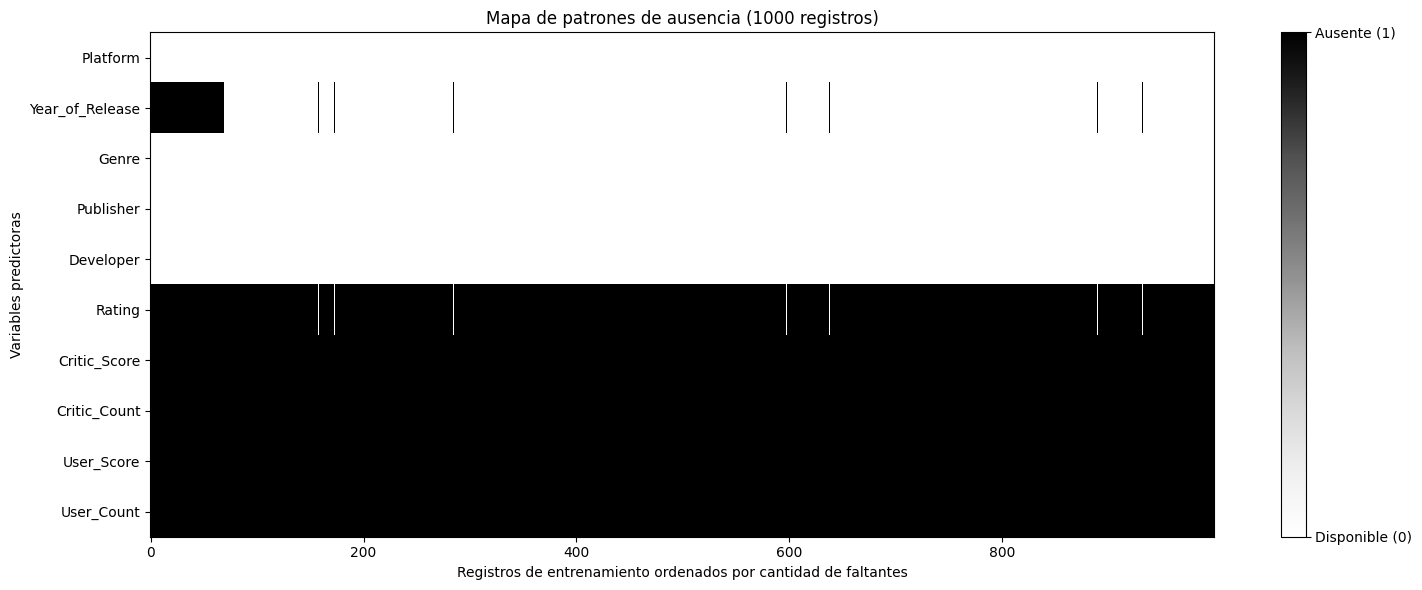

In [11]:
# Ordenar filas por cantidad de valores faltantes.
orden_filas = M_train.sum(axis=1).sort_values(
    ascending=False
).index

M_ordenada = M_train.loc[orden_filas]

# Mostrar hasta 1,000 filas para mantener legible la figura.
n_mostrar = min(1000, len(M_ordenada))
M_muestra = M_ordenada.iloc[:n_mostrar]

fig, ax = plt.subplots(figsize=(15, 6))

imagen = ax.imshow(
    M_muestra.T.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="Greys",
    vmin=0,
    vmax=1
)

ax.set_yticks(np.arange(len(FEATURES)))
ax.set_yticklabels(FEATURES)
ax.set_xlabel("Registros de entrenamiento ordenados por cantidad de faltantes")
ax.set_ylabel("Variables predictoras")
ax.set_title(
    f"Mapa de patrones de ausencia ({n_mostrar} registros)"
)

barra = fig.colorbar(imagen, ax=ax, ticks=[0, 1])
barra.ax.set_yticklabels(["Disponible (0)", "Ausente (1)"])

fig.tight_layout()
fig.savefig(
    OUTPUT32_DIR / "mapa_patrones_ausencia_train.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 3.2.2 Mecanismo de ausencia: MCAR, MAR o MNAR

Se estudia si la probabilidad de que falte cada variable se relaciona con otras variables observadas. Para cada columna con faltantes, se compara el resto de las variables:

- **Numéricas:** prueba \(t\) de Welch entre registros con dato disponible y registros con dato ausente.
- **Categóricas:** prueba chi-cuadrado (\(\chi^2\)) entre la categoría observada y el indicador de ausencia.

Las comparaciones se realizan exclusivamente con los registros de entrenamiento. Se excluyen `Name`, por ser un identificador de alta cardinalidad, y `Year_missing`, porque es una variable derivada directamente de `Year_of_Release` y produciría una relación tautológica al estudiar la ausencia del año.

Se incluyen `Is_Hit` y las ventas únicamente como variables de diagnóstico de la ausencia; no se utilizarán para imputar ni para entrenar el modelo. Para las pruebas categóricas se agrupan categorías poco frecuentes y se comprueba la frecuencia esperada de chi-cuadrado. Los valores \(p\) se ajustan mediante Benjamini-Hochberg para controlar comparaciones múltiples.

**Interpretación:** una asociación significativa aporta evidencia contra MCAR y es compatible con MAR, pero no demuestra MAR. La falta de asociaciones significativas tampoco demuestra MCAR. MNAR no puede confirmarse únicamente con pruebas sobre variables observadas: requiere un argumento sobre el proceso que generó la ausencia y debe presentarse como hipótesis cuando no se puede comprobar.

In [12]:
# Dataset de entrenamiento para analizar la ausencia.
df_train_mecanismos = df_32.iloc[train_indices].copy()

columnas_con_nulos = [
    c for c in FEATURES
    if df_train_mecanismos[c].isna().any()
]

# Name se excluye por ser identificador y Year_missing por ser derivada.
COVARIABLES = [
    c for c in df_train_mecanismos.columns
    if c not in ["Name", "Year_missing"]
]

# Is_Hit es binaria y se trata como categórica en estas pruebas.
CATEGORICAS_TEST = [
    "Platform", "Genre", "Publisher", "Developer", "Rating", "Is_Hit"
]

def agrupar_categorias_frecuentes(serie, minimo=30):
    """Agrupa categorías con menos de 'minimo' observaciones en OTROS."""
    s = serie.dropna().astype(str)
    frecuencias = s.value_counts()
    frecuentes = frecuencias[frecuencias >= minimo].index
    return s.where(s.isin(frecuentes), other="OTROS")


resultados_pruebas = []

for variable_con_nulos in columnas_con_nulos:
    indicador = df_train_mecanismos[variable_con_nulos].isna().astype(int)
    for covariable in COVARIABLES:
        if covariable == variable_con_nulos:
            continue
        # Se excluyen observaciones donde la covariable comparada
        # también está ausente.
        datos = pd.DataFrame({
            "covariable": df_train_mecanismos[covariable],
            "M": indicador
        }).dropna()

        grupo_disponible = datos.loc[
            datos["M"] == 0, "covariable"
        ]
        grupo_ausente = datos.loc[
            datos["M"] == 1, "covariable"
        ]

        if len(grupo_disponible) < 3 or len(grupo_ausente) < 3:
            resultados_pruebas.append({
                "Variable_con_nulos": variable_con_nulos,
                "Covariable": covariable,
                "Prueba": "No ejecutada",
                "Estadistico": np.nan,
                "P_value": np.nan,
                "Detalle": "Menos de 3 observaciones en uno de los grupos"
            })
            continue

        if covariable in CATEGORICAS_TEST or not pd.api.types.is_numeric_dtype(datos["covariable"]):
            categorias = agrupar_categorias_frecuentes(
                datos["covariable"],
                minimo=30
            )

            tabla_datos = pd.DataFrame({
                "categoria": categorias,
                "M": datos.loc[categorias.index, "M"]
            })

            tabla = pd.crosstab(
                tabla_datos["categoria"],
                tabla_datos["M"]
            )

            if tabla.shape[0] < 2 or tabla.shape[1] < 2:
                resultados_pruebas.append({
                    "Variable_con_nulos": variable_con_nulos,
                    "Covariable": covariable,
                    "Prueba": "Chi-cuadrado no ejecutada",
                    "Estadistico": np.nan,
                    "P_value": np.nan,
                    "Detalle": "La tabla no contiene al menos 2 filas y 2 columnas"
                })
                continue

            chi2, p_value, gl, esperados = chi2_contingency(tabla)

            if (esperados < 5).any():
                resultados_pruebas.append({
                    "Variable_con_nulos": variable_con_nulos,
                    "Covariable": covariable,
                    "Prueba": "Chi-cuadrado no concluyente",
                    "Estadistico": chi2,
                    "P_value": np.nan,
                    "Detalle": (
                        "Se detectaron frecuencias esperadas menores que 5; "
                        "no se usa el p-value asintótico"
                    )
                })
            else:
                resultados_pruebas.append({
                    "Variable_con_nulos": variable_con_nulos,
                    "Covariable": covariable,
                    "Prueba": "Chi-cuadrado",
                    "Estadistico": chi2,
                    "P_value": p_value,
                    "Detalle": f"Grados de libertad: {gl}; frecuencias esperadas >= 5"
                })

        else:
            grupo_0 = pd.to_numeric(
                grupo_disponible, errors="coerce"
            ).dropna()

            grupo_1 = pd.to_numeric(
                grupo_ausente, errors="coerce"
            ).dropna()

            if len(grupo_0) < 3 or len(grupo_1) < 3:
                resultados_pruebas.append({
                    "Variable_con_nulos": variable_con_nulos,
                    "Covariable": covariable,
                    "Prueba": "t de Welch no ejecutada",
                    "Estadistico": np.nan,
                    "P_value": np.nan,
                    "Detalle": "Menos de 3 observaciones numéricas por grupo"
                })
                continue

            estadistico, p_value = ttest_ind(
                grupo_0,
                grupo_1,
                equal_var=False,
                nan_policy="omit"
            )

            resultados_pruebas.append({
                "Variable_con_nulos": variable_con_nulos,
                "Covariable": covariable,
                "Prueba": "t de Welch",
                "Estadistico": estadistico,
                "P_value": p_value,
                "Detalle": (
                    f"Media M=0: {grupo_0.mean():.4f}; "
                    f"media M=1: {grupo_1.mean():.4f}"
                )
            })


resultados_mecanismos = pd.DataFrame(resultados_pruebas)

# Ajuste Benjamini-Hochberg sin requerir paquetes adicionales.
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)

    orden = np.argsort(p_values)
    p_ordenados = p_values[orden]

    q_ordenados = p_ordenados * n / np.arange(1, n + 1)
    q_ordenados = np.minimum.accumulate(q_ordenados[::-1])[::-1]
    q_ordenados = np.clip(q_ordenados, 0, 1)

    q_values = np.empty(n, dtype=float)
    q_values[orden] = q_ordenados
    return q_values


resultados_mecanismos["P_ajustado_BH"] = np.nan
mascara_p = resultados_mecanismos["P_value"].notna()

if mascara_p.any():
    resultados_mecanismos.loc[mascara_p, "P_ajustado_BH"] = (
        benjamini_hochberg(
            resultados_mecanismos.loc[mascara_p, "P_value"].to_numpy()
        )
    )

resultados_mecanismos["Asociacion_significativa_BH"] = (
    resultados_mecanismos["P_ajustado_BH"] < 0.05
)

print("Resultados de pruebas por columna con faltantes:")
display(
    resultados_mecanismos.sort_values(
        ["Variable_con_nulos", "P_ajustado_BH"],
        na_position="last"
    ).round(5)
)

resultados_mecanismos.to_csv(
    OUTPUT32_DIR / "resultados_pruebas_mecanismos.csv",
    index=False,
    encoding="utf-8-sig"
)

Resultados de pruebas por columna con faltantes:


,Variable_con_nulos,Covariable,Prueba,Estadistico,P_value,Detalle,P_ajustado_BH,Asociacion_significativa_BH
45,Critic_Count,Platform,Chi-cuadrado,2762.59533,0.00000,Grados de libertad: 23; frecuencias esperadas ...,0.00000,True
48,Critic_Count,Publisher,Chi-cuadrado,1713.96915,0.00000,Grados de libertad: 58; frecuencias esperadas ...,0.00000,True
57,Critic_Count,Developer,Chi-cuadrado,8590.07494,0.00000,Grados de libertad: 38; frecuencias esperadas ...,0.00000,True
47,Critic_Count,Genre,Chi-cuadrado,792.97103,0.00000,Grados de libertad: 11; frecuencias esperadas ...,0.00000,True
59,Critic_Count,Is_Hit,Chi-cuadrado,455.70145,0.00000,Grados de libertad: 1; frecuencias esperadas >= 5,0.00000,True
...,...,...,...,...,...,...,...,...
10,Year_of_Release,User_Score,t de Welch,0.22358,0.82352,Media M=0: 7.1257; media M=1: 7.0912,0.83422,False
0,Year_of_Release,Platform,Chi-cuadrado no concluyente,142.41673,NaN,Se detectaron frecuencias esperadas menores qu...,NaN,False
2,Year_of_Release,Publisher,Chi-cuadrado no concluyente,3100.26699,NaN,Se detectaron frecuencias esperadas menores qu...,NaN,False
12,Year_of_Release,Developer,Chi-cuadrado no concluyente,117.37472,NaN,Se detectaron frecuencias esperadas menores qu...,NaN,False


In [13]:
resumen_mecanismos = (
    resultados_mecanismos
    .groupby("Variable_con_nulos")
    .agg(
        Pruebas_validas=("P_ajustado_BH", "count"),
        Asociaciones_significativas=(
            "Asociacion_significativa_BH", "sum"
        ),
        Menor_p_ajustado=("P_ajustado_BH", "min")
    )
    .reset_index()
)

def interpretar_evidencia(fila):
    if fila["Asociaciones_significativas"] > 0:
        return (
            "Se detectó asociación con variables observadas; "
            "evidencia contra MCAR y compatible con MAR"
        )
    return (
        "No se detectó asociación significativa; MCAR no se descarta, pero no queda demostrado"
    )

resumen_mecanismos["Lectura_estadistica"] = (
    resumen_mecanismos.apply(interpretar_evidencia, axis=1)
)

print("Resumen estadístico (no es una clasificación definitiva del mecanismo):")
display(resumen_mecanismos)

resumen_mecanismos.to_csv(
    OUTPUT32_DIR / "resumen_evidencia_mecanismos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Mostrar asociaciones significativas tras ajuste BH.
asociaciones = resultados_mecanismos[
    resultados_mecanismos["Asociacion_significativa_BH"] == True
].sort_values("P_ajustado_BH")

print("\nAsociaciones estadísticamente significativas:")
display(asociaciones)

Resumen estadístico (no es una clasificación definitiva del mecanismo):


,Variable_con_nulos,Pruebas_validas,Asociaciones_significativas,Menor_p_ajustado,Lectura_estadistica
0,Critic_Count,13,13,0.000000e+00,Se detectó asociación con variables observadas...
1,Critic_Score,13,13,0.000000e+00,Se detectó asociación con variables observadas...
2,Rating,15,12,0.000000e+00,Se detectó asociación con variables observadas...
3,User_Count,13,13,0.000000e+00,Se detectó asociación con variables observadas...
4,User_Score,13,13,0.000000e+00,Se detectó asociación con variables observadas...
5,Year_of_Release,11,5,4.169397e-13,Se detectó asociación con variables observadas...



Asociaciones estadísticamente significativas:


,Variable_con_nulos,Covariable,Prueba,Estadistico,P_value,Detalle,P_ajustado_BH,Asociacion_significativa_BH
15,Rating,Platform,Chi-cuadrado,3186.745802,0.000000e+00,Grados de libertad: 23; frecuencias esperadas ...,0.000000e+00,True
18,Rating,Publisher,Chi-cuadrado,2365.561261,0.000000e+00,Grados de libertad: 58; frecuencias esperadas ...,0.000000e+00,True
28,Rating,Developer,Chi-cuadrado,12902.081461,0.000000e+00,Grados de libertad: 38; frecuencias esperadas ...,0.000000e+00,True
30,Critic_Score,Platform,Chi-cuadrado,2762.595329,0.000000e+00,Grados de libertad: 23; frecuencias esperadas ...,0.000000e+00,True
45,Critic_Count,Platform,Chi-cuadrado,2762.595329,0.000000e+00,Grados de libertad: 23; frecuencias esperadas ...,0.000000e+00,True
...,...,...,...,...,...,...,...,...
4,Year_of_Release,EU_Sales,t de Welch,6.186822,1.950405e-09,Media M=0: 0.1471; media M=1: 0.0788,2.340486e-09,True
7,Year_of_Release,Global_Sales,t de Welch,4.471289,1.146694e-05,Media M=0: 0.5400; media M=1: 0.3485,1.355184e-05,True
25,Rating,Critic_Count,t de Welch,4.330017,5.190404e-05,Media M=0: 26.5863; media M=1: 19.6406,6.042560e-05,True
6,Year_of_Release,Other_Sales,t de Welch,4.067138,6.230233e-05,Media M=0: 0.0477; media M=1: 0.0280,7.146444e-05,True


##### Argumento del dominio y clasificación razonada

La clasificación final no debe asignarse únicamente a partir del valor \(p\). Para cada variable con faltantes se debe combinar:

1. La evidencia de las comparaciones estadísticas anteriores.
2. El conocimiento del proceso mediante el cual se generan o recopilan esos atributos.
3. La posibilidad de que la ausencia dependa de variables no observadas.

Las siguientes son hipótesis de dominio que deben contrastarse con los resultados estadísticos; no son conclusiones automáticas:

| Variable | Argumento de dominio que debe evaluarse |
|---|---|
| `Year_of_Release` | La ausencia puede relacionarse con registros históricos o metadatos incompletos. Se debe comprobar si se asocia con plataforma, género, editorial o ventas. La dependencia del año verdadero no observado sería una hipótesis MNAR, no demostrable con este archivo. |
| `Critic_Score` | Puede faltar cuando un videojuego no recibió cobertura o puntuaciones de críticos. La cobertura puede relacionarse con año, plataforma, editorial y popularidad (MAR plausible); también puede depender de la existencia de evaluaciones no observadas (posible MNAR). |
| `Critic_Count` | El número de evaluaciones puede faltar cuando no se registraron críticas para el título. Debe revisarse junto con `Critic_Score`, porque ambos pueden compartir el patrón de ausencia. |
| `User_Score` | Puede faltar cuando no hubo suficientes usuarios que emitieran una puntuación. La participación y la popularidad pueden estar relacionadas con variables observadas, pero también existe una posible dependencia del proceso no observado de respuesta (hipótesis MNAR). |
| `User_Count` | La cantidad de valoraciones puede faltar cuando no se registraron votos de usuarios. Debe examinarse junto con `User_Score`, pues ambos atributos pueden compartir el mismo patrón. |
| `Rating` | La clasificación por edades puede no estar disponible en determinados registros, plataformas o periodos. La relación con plataforma, año y editorial puede apoyar una explicación MAR; la ausencia del proceso de clasificación podría sugerir una hipótesis MNAR. |

**Criterio de redacción:** si una columna presenta asociaciones estadísticamente significativas con otras variables observadas, se puede argumentar que MCAR no es una explicación suficiente y que MAR es compatible con la evidencia. Si no se encuentran asociaciones, se debe escribir “no se detectó evidencia contra MCAR”, no “se demostró MCAR”. MNAR debe expresarse como una posibilidad respaldada por el dominio y no como un resultado probado por estas pruebas.

### 3.2.3 Regla de faltantes controlados

La consigna solicita generar faltantes artificiales cuando el dataset no tenga faltantes o tenga muy pocos. En este proyecto existen ausencias naturales en seis variables predictoras, y cinco de ellas presentan porcentajes sustanciales. Por ello, se establece que no es necesario introducir faltantes controlados adicionales.

Para hacer explícita esta decisión, se utiliza una regla operativa: se considera que hay suficientes faltantes naturales cuando al menos tres variables predictoras presentan un porcentaje de ausencia igual o superior al 5 % en el conjunto de entrenamiento.

La ocultación controlada de valores conocidos que se realiza en el experimento de reconstrucción de la siguiente sección tiene otro propósito: medir el error de imputación. No debe confundirse con la generación adicional de un dataset artificial MCAR/MAR.

In [14]:
porcentaje_nulos_train = X_train_32.isna().mean() * 100

# Regla operativa declarada:
# hay suficientes faltantes naturales si al menos 3 predictoras
# tienen >= 5% de ausencia.
columnas_con_ausencia_suficiente = (
    porcentaje_nulos_train[porcentaje_nulos_train >= 5].index.tolist()
)

GENERAR_FALTANTES_CONTROLADOS = (
    len(columnas_con_ausencia_suficiente) < 3
)

print("Porcentaje de faltantes por predictor:")
display(porcentaje_nulos_train.sort_values(ascending=False).round(2))

print(
    "\nColumnas con al menos 5% de faltantes:",
    columnas_con_ausencia_suficiente
)

print(
    "\n¿Es necesario generar faltantes controlados adicionales?",
    GENERAR_FALTANTES_CONTROLADOS
)

if GENERAR_FALTANTES_CONTROLADOS:
    print(
        "El criterio indica que sería necesario diseñar una copia "
        "experimental con faltantes MCAR y MAR."
    )
else:
    print(
        "No se generan faltantes controlados adicionales: el dataset ya contiene suficientes ausencias naturales en las variables predictoras."
    )


Porcentaje de faltantes por predictor:


User_Count         54.53
User_Score         54.53
Critic_Score       51.48
Critic_Count       51.48
Rating             40.55
Year_of_Release     1.62
Platform            0.00
Developer           0.00
Genre               0.00
Publisher           0.00
dtype: float64


Columnas con al menos 5% de faltantes: ['Rating', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']

¿Es necesario generar faltantes controlados adicionales? False
No se generan faltantes controlados adicionales: el dataset ya contiene suficientes ausencias naturales en las variables predictoras.


### 3.2.4 Experimento de imputación: error de reconstrucción

Se evalúan seis alternativas:

1. Eliminación por listas.
2. Media para numéricas y moda para categóricas.
3. Mediana para numéricas y moda para categóricas.
4. KNN con \(K=3\) para numéricas y moda para categóricas.
5. KNN con \(K=5\) para numéricas y moda para categóricas.
6. Imputación iterativa para numéricas y moda para categóricas.

Para medir la reconstrucción se oculta aleatoriamente el 20 % de los valores que originalmente están disponibles en cada columna predictora del conjunto de entrenamiento. La misma selección de posiciones ocultas se utiliza para todos los métodos.

Los imputadores se ajustan únicamente con la copia enmascarada del entrenamiento. Los valores originalmente ausentes continúan ausentes durante la simulación y se imputan también. No se utiliza el conjunto de prueba.

Para variables numéricas se calculan MAE y RMSE; para categóricas, la tasa de acierto. También se compara la varianza de cada variable antes y después de imputar. La eliminación por listas no reconstruye los valores, por lo que se evalúa mediante cobertura de registros y cambio de varianza, no mediante MAE/RMSE.

In [15]:
#Preparación para todo el show

METODOS_IMPUTACION = [
    "media_moda",
    "mediana_moda",
    "knn_3",
    "knn_5",
    "iterativa"
]

def limitar_rangos_dominio(X):
    """
    Aplica restricciones conocidas después de imputar:
    año dentro del periodo del dataset, puntuaciones dentro
    de sus escalas y conteos no negativos e enteros.
    """
    X = X.copy()

    if "Year_of_Release" in X:
        X["Year_of_Release"] = (
            X["Year_of_Release"].clip(1980, 2016).round()
        )

    if "Critic_Score" in X:
        X["Critic_Score"] = X["Critic_Score"].clip(0, 100)

    if "User_Score" in X:
        X["User_Score"] = X["User_Score"].clip(0, 10)

    for columna in ["Critic_Count", "User_Count"]:
        if columna in X:
            X[columna] = X[columna].clip(lower=0).round()

    return X


def imputar_dataframe(X_entrada, metodo):
    """
    Ajusta el imputador con X_entrada y devuelve un DataFrame
    con las columnas e índices originales.

    Para KNN e imputación iterativa se estandarizan las numéricas
    antes de imputar, se invierte la escala y se aplican límites
    de dominio.
    """
    X_salida = X_entrada.copy()

    # Variables numéricas.
    X_num = X_entrada[NUM_COLS].astype(float)

    if metodo == "media_moda":
        imputador_num = SimpleImputer(strategy="mean")
        arreglo_num = imputador_num.fit_transform(X_num)

    elif metodo == "mediana_moda":
        imputador_num = SimpleImputer(strategy="median")
        arreglo_num = imputador_num.fit_transform(X_num)

    elif metodo in ["knn_3", "knn_5"]:
        k = 3 if metodo == "knn_3" else 5

        escalador = StandardScaler()
        X_escalado = escalador.fit_transform(X_num)

        imputador_num = KNNImputer(
            n_neighbors=k,
            weights="distance"
        )
        arreglo_escalado = imputador_num.fit_transform(X_escalado)

        arreglo_num = escalador.inverse_transform(arreglo_escalado)

    elif metodo == "iterativa":
        escalador = StandardScaler()
        X_escalado = escalador.fit_transform(X_num)

        imputador_num = IterativeImputer(
            max_iter=10,
            initial_strategy="median",
            random_state=42
        )
        arreglo_escalado = imputador_num.fit_transform(X_escalado)

        arreglo_num = escalador.inverse_transform(arreglo_escalado)

    else:
        raise ValueError(f"Método desconocido: {metodo}")

    X_salida.loc[:, NUM_COLS] = pd.DataFrame(
        arreglo_num,
        index=X_entrada.index,
        columns=NUM_COLS
    )

    # Variables categóricas: moda.
    imputador_cat = SimpleImputer(strategy="most_frequent")
    arreglo_cat = imputador_cat.fit_transform(X_entrada[CAT_COLS])

    X_salida.loc[:, CAT_COLS] = pd.DataFrame(
        arreglo_cat,
        index=X_entrada.index,
        columns=CAT_COLS
    )

    # Aplicar rangos válidos y restricciones de variables discretas.
    X_salida = limitar_rangos_dominio(X_salida)

    return X_salida

##### Ocultamiento reproducible de valores conocidos

La máscara de evaluación se genera una sola vez. Así todos los imputadores reconstruyen exactamente las mismas celdas ocultas y la comparación es justa. Se conserva un diccionario con los valores verdaderos para calcular los errores.

In [16]:
PROPORCION_OCULTAR = 0.20
SEMILLA_RECONSTRUCCION = 2026

rng_reconstruccion = np.random.default_rng(SEMILLA_RECONSTRUCCION)

# Copia de entrenamiento que será enmascarada.
X_train_enmascarado = X_train_32.copy()

# Diccionario: columna -> valores verdaderos ocultados.
valores_verdaderos_ocultos = {}

for columna in FEATURES:

    indices_disponibles = X_train_32.index[
        X_train_32[columna].notna()
    ].to_numpy()

    n_ocultar = int(round(PROPORCION_OCULTAR * len(indices_disponibles)))

    if n_ocultar == 0:
        continue

    indices_ocultos = rng_reconstruccion.choice(
        indices_disponibles,
        size=n_ocultar,
        replace=False
    )

    valores_verdaderos_ocultos[columna] = (
        X_train_32.loc[indices_ocultos, columna].copy()
    )

    X_train_enmascarado.loc[
        indices_ocultos, columna
    ] = np.nan

resumen_ocultamiento = pd.DataFrame({
    "Variable": list(valores_verdaderos_ocultos.keys()),
    "Valores_ocultados": [
        len(v) for v in valores_verdaderos_ocultos.values()
    ],
    "Porcentaje_sobre_valores_observados": [
        len(valores_verdaderos_ocultos[c]) /
        X_train_32[c].notna().sum() * 100
        for c in valores_verdaderos_ocultos
    ]
})

print("Resumen del ocultamiento de valores conocidos:")
display(resumen_ocultamiento.round(2))

print("\nCantidad de faltantes antes y después del ocultamiento:")
comparacion_mascara = pd.DataFrame({
    "Nulos_train_original": X_train_32.isna().sum(),
    "Nulos_train_enmascarado": X_train_enmascarado.isna().sum()
})
display(comparacion_mascara)

Resumen del ocultamiento de valores conocidos:


,Variable,Valores_ocultados,Porcentaje_sobre_valores_observados
0,Platform,2674,20.00
1,Year_of_Release,2631,20.00
2,Genre,2674,20.00
3,Publisher,2674,20.00
4,Developer,2674,20.00
5,Rating,1590,20.01
6,Critic_Score,1297,19.99
7,Critic_Count,1297,19.99
8,User_Score,1216,20.00
9,User_Count,1216,20.00



Cantidad de faltantes antes y después del ocultamiento:


,Nulos_train_original,Nulos_train_enmascarado
Platform,0,2674
Year_of_Release,217,2848
Genre,0,2674
Publisher,0,2674
Developer,0,2674
Rating,5422,7012
Critic_Score,6883,8180
Critic_Count,6883,8180
User_Score,7290,8506
User_Count,7290,8506


#### Comparación de los cinco métodos de reconstrucción

En cada método se mide el error únicamente en las posiciones que se ocultaron de manera artificial. Los faltantes naturales no tienen un valor verdadero conocido y, por tanto, no participan en el cálculo del error.

El cambio de varianza se calcula comparando la varianza observada en los datos de entrenamiento antes de imputar con la varianza de la columna completa después de imputar.

In [17]:
#Evaluar recontruccion para cada imputador
resultados_reconstruccion = []
datos_imputados_reconstruccion = {}

for metodo in METODOS_IMPUTACION:
    print(f"Imputando con: {metodo}")

    X_imputado = imputar_dataframe(
        X_train_enmascarado,
        metodo
    )

    datos_imputados_reconstruccion[metodo] = X_imputado

    for columna, valores_reales in valores_verdaderos_ocultos.items():
        predicciones = X_imputado.loc[
            valores_reales.index, columna
        ]

        es_numerica = columna in NUM_COLS

        if es_numerica:
            reales = pd.to_numeric(valores_reales, errors="coerce").to_numpy()
            estimados = pd.to_numeric(predicciones, errors="coerce").to_numpy()

            error = reales - estimados

            mae = float(np.mean(np.abs(error)))
            rmse = float(np.sqrt(np.mean(error ** 2)))
            tasa_acierto = np.nan

            varianza_original = float(X_train_32[columna].var())
            varianza_imputada = float(X_imputado[columna].var())

            if pd.notna(varianza_original) and varianza_original != 0:
                cambio_varianza = (
                    (varianza_imputada - varianza_original)
                    / varianza_original
                ) * 100
            else:
                cambio_varianza = np.nan

        else:
            reales = valores_reales.astype(str).to_numpy()
            estimados = predicciones.astype(str).to_numpy()

            tasa_acierto = float(np.mean(reales == estimados))
            mae = np.nan
            rmse = np.nan
            varianza_original = np.nan
            varianza_imputada = np.nan
            cambio_varianza = np.nan

        resultados_reconstruccion.append({
            "Metodo": metodo,
            "Variable": columna,
            "Tipo": "Numerica" if es_numerica else "Categorica",
            "N_ocultos_evaluados": len(valores_reales),
            "MAE": mae,
            "RMSE": rmse,
            "Tasa_acierto": tasa_acierto,
            "Varianza_original": varianza_original,
            "Varianza_imputada": varianza_imputada,
            "Cambio_varianza_pct": cambio_varianza
        })


resultados_reconstruccion = pd.DataFrame(resultados_reconstruccion)

print("Resultados de reconstrucción:")
display(resultados_reconstruccion.round(4))

resultados_reconstruccion.to_csv(
    OUTPUT32_DIR / "resultados_reconstruccion.csv",
    index=False,
    encoding="utf-8-sig"
)

Imputando con: media_moda
Imputando con: mediana_moda
Imputando con: knn_3
Imputando con: knn_5
Imputando con: iterativa
Resultados de reconstrucción:


c:\Users\dante\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,Metodo,Variable,Tipo,N_ocultos_evaluados,MAE,RMSE,Tasa_acierto,Varianza_original,Varianza_imputada,Cambio_varianza_pct
0,media_moda,Platform,Categorica,2674,NaN,NaN,0.1230,NaN,NaN,NaN
1,media_moda,Year_of_Release,Numerica,2631,4.5241,6.0081,NaN,34.6619,27.1089,-21.7905
2,media_moda,Genre,Categorica,2674,NaN,NaN,0.2098,NaN,NaN,NaN
3,media_moda,Publisher,Categorica,2674,NaN,NaN,0.0804,NaN,NaN,NaN
4,media_moda,Developer,Categorica,2674,NaN,NaN,0.4144,NaN,NaN,NaN
5,media_moda,Rating,Categorica,1590,NaN,NaN,0.3981,NaN,NaN,NaN
6,media_moda,Critic_Score,Numerica,1297,10.9272,13.8758,NaN,195.4625,76.1500,-61.0411
7,media_moda,Critic_Count,Numerica,1297,15.5975,19.4073,NaN,364.7033,140.4918,-61.4778
8,media_moda,User_Score,Numerica,1216,1.1535,1.5217,NaN,2.2374,0.8068,-63.9405
9,media_moda,User_Count,Numerica,1216,230.1184,661.0798,NaN,295782.8832,94751.6907,-67.9658


##### Eliminación por listas

La eliminación por listas descarta cualquier fila que contenga al menos un faltante en las diez variables predictoras. Como no reconstruye valores, no se le asignan MAE, RMSE ni tasa de acierto. Se mide el porcentaje de registros que conserva y el cambio de varianza en las variables numéricas.

In [18]:
#Evaluar eliminacion por listas
X_train_completos = X_train_32.dropna(axis=0, how="any")

n_train_original = len(X_train_32)
n_train_completo = len(X_train_completos)
n_train_eliminado = n_train_original - n_train_completo

cobertura_eliminacion = (
    n_train_completo / n_train_original * 100
)

print("Eliminación por listas")
print("----------------------")
print("Registros de entrenamiento:", n_train_original)
print("Registros completos conservados:", n_train_completo)
print("Registros eliminados:", n_train_eliminado)
print(f"Cobertura: {cobertura_eliminacion:.2f}%")

resultados_eliminacion = []

for columna in NUM_COLS:
    var_original = X_train_32[columna].var()
    var_completos = X_train_completos[columna].var()

    if pd.notna(var_original) and var_original != 0:
        cambio = (
            (var_completos - var_original) / var_original
        ) * 100
    else:
        cambio = np.nan

    resultados_eliminacion.append({
        "Variable": columna,
        "Varianza_original": var_original,
        "Varianza_casos_completos": var_completos,
        "Cambio_varianza_pct": cambio
    })

resultados_eliminacion = pd.DataFrame(resultados_eliminacion)
display(resultados_eliminacion.round(4))

resultados_eliminacion.to_csv(
    OUTPUT32_DIR / "resultados_eliminacion_listas.csv",
    index=False,
    encoding="utf-8-sig"
)

Eliminación por listas
----------------------
Registros de entrenamiento: 13370
Registros completos conservados: 5463
Registros eliminados: 7907
Cobertura: 40.86%


,Variable,Varianza_original,Varianza_casos_completos,Cambio_varianza_pct
0,Year_of_Release,34.6619,17.7391,-48.8226
1,Critic_Score,195.4625,193.0430,-1.2378
2,Critic_Count,364.7033,374.3598,2.6478
3,User_Score,2.2374,2.0521,-8.2805
4,User_Count,295782.8832,323409.5353,9.3402


### 3.2.5 Efecto de la imputación en el modelo

Se utilizará el clasificador ganador del Parcial I: Regresión Logística con `max_iter=2000`, `solver="liblinear"`, `class_weight="balanced"` y `random_state=42`.

La evaluación se realizará con cinco folds estratificados sobre el conjunto de entrenamiento. Las transformaciones se incorporan dentro de una `Pipeline` y un `ColumnTransformer`, de forma que cada imputador se ajusta únicamente con el fold de entrenamiento y se aplica al fold de validación. Esto evita fuga de información.

Se evaluarán eliminación por listas, media/moda, mediana/moda, KNN con \(K=3\), KNN con \(K=5\) e imputación iterativa. La métrica principal será F1; también se reportarán accuracy, precision, recall, ROC-AUC y cobertura de validación.

In [19]:
#Definicion del modelo original del parcial 1
BEST_ESTIMATOR = LogisticRegression(
    max_iter=2000,
    solver="liblinear",
    class_weight="balanced",
    random_state=42
)

cv_32 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Clasificador:", BEST_ESTIMATOR)
print("Validación cruzada: 5 folds estratificados")
print("random_state:", cv_32.random_state)

Clasificador: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42,
                   solver='liblinear')
Validación cruzada: 5 folds estratificados
random_state: 42


##### Construcción de las pipelines

Para media y mediana se imputa primero y después se estandariza, como en el Parcial I. Para KNN e imputación iterativa se estandarizan las variables numéricas antes de estimar los valores, de modo que las variables con escalas grandes no dominen las distancias o los modelos iterativos.

Las variables categóricas se imputan mediante la moda y se transforman con One-Hot Encoding. `MissingIndicator` se añadirá en una comparación adicional, no por defecto.

In [20]:
#Construir el pipeline para cada estrategia
def crear_pipeline_modelo(metodo, agregar_indicadores=False):
    """
    Construye la pipeline completa para validación cruzada.

    metodo:
        eliminacion, media_moda, mediana_moda, knn_3,
        knn_5 o iterativa.

    agregar_indicadores:
        agrega una columna binaria por cada predictora que indique
        si el dato estaba ausente antes de la imputación.
    """

    transformadores = []

    #Rama numerica
    if metodo == "eliminacion":
        pipeline_numerica = Pipeline([
            ("escalado", StandardScaler())
        ])

    elif metodo == "media_moda":
        pipeline_numerica = Pipeline([
            ("imputacion", SimpleImputer(strategy="mean")),
            ("escalado", StandardScaler())
        ])

    elif metodo == "mediana_moda":
        pipeline_numerica = Pipeline([
            ("imputacion", SimpleImputer(strategy="median")),
            ("escalado", StandardScaler())
        ])

    elif metodo in ["knn_3", "knn_5"]:
        k = 3 if metodo == "knn_3" else 5
        pipeline_numerica = Pipeline([
            # StandardScaler conserva los NaN para KNNImputer.
            ("escalado", StandardScaler()),
            ("imputacion", KNNImputer(
                n_neighbors=k,
                weights="distance"
            ))
        ])

    elif metodo == "iterativa":
        pipeline_numerica = Pipeline([
            ("escalado", StandardScaler()),
            ("imputacion", IterativeImputer(
                max_iter=10,
                initial_strategy="median",
                random_state=42
            ))
        ])

    else:
        raise ValueError(f"Estrategia desconocida: {metodo}")

    transformadores.append(
        ("numericas", pipeline_numerica, NUM_COLS)
    )

    #Rama categorica
    if metodo == "eliminacion":
        pipeline_categorica = Pipeline([
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])
    else:
        pipeline_categorica = Pipeline([
            ("imputacion", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])

    transformadores.append(
        ("categoricas", pipeline_categorica, CAT_COLS)
    )

    #Indicadorres de ausencia
    if agregar_indicadores:
        transformadores.append(
            (
                "indicadores_ausencia",
                MissingIndicator(features="all"),
                FEATURES
            )
        )

    preprocesador = ColumnTransformer(
        transformers=transformadores,
        remainder="drop"
    )

    pipeline = Pipeline([
        ("preprocessor", preprocesador),
        ("model", clone(BEST_ESTIMATOR))
    ])

    return pipeline

##### Validación cruzada para las estrategias de imputación

Para los cinco métodos que imputan datos se utiliza `cross_validate`, que ajusta la pipeline dentro de cada fold. En eliminación por listas, los registros incompletos se descartan por separado en cada fold y se informa la cobertura, pues el F1 se calcula sobre menos registros que en los métodos de imputación.

In [21]:
#Función de metricas y validación cruzada
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

def evaluar_eliminacion_cv(X, y, cv):
    """
    Validación cruzada de eliminación por listas.
    En cada fold se eliminan filas incompletas tanto del
    entrenamiento como de la validación de ese fold.
    """
    filas = []

    for numero_fold, (idx_train, idx_val) in enumerate(cv.split(X, y), start=1):

        X_fold_train = X.iloc[idx_train].copy()
        y_fold_train = y.iloc[idx_train].copy()

        X_fold_val = X.iloc[idx_val].copy()
        y_fold_val = y.iloc[idx_val].copy()

        mask_train = X_fold_train.notna().all(axis=1)
        mask_val = X_fold_val.notna().all(axis=1)

        X_fold_train = X_fold_train.loc[mask_train]
        y_fold_train = y_fold_train.loc[mask_train]

        X_fold_val = X_fold_val.loc[mask_val]
        y_fold_val = y_fold_val.loc[mask_val]

        if (
            len(X_fold_train) == 0
            or len(X_fold_val) == 0
            or y_fold_train.nunique() < 2
            or y_fold_val.nunique() < 2
        ):
            continue

        modelo = crear_pipeline_modelo("eliminacion")
        modelo.fit(X_fold_train, y_fold_train)

        pred = modelo.predict(X_fold_val)
        prob = modelo.predict_proba(X_fold_val)[:, 1]

        filas.append({
            "Metodo": "eliminacion",
            "Fold": numero_fold,
            "Accuracy": accuracy_score(y_fold_val, pred),
            "Precision": precision_score(y_fold_val, pred, zero_division=0),
            "Recall": recall_score(y_fold_val, pred, zero_division=0),
            "F1": f1_score(y_fold_val, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_fold_val, prob),
            "N_validacion_original": len(idx_val),
            "N_validacion_evaluada": len(y_fold_val),
            "Cobertura_pct": len(y_fold_val) / len(idx_val) * 100
        })

    return pd.DataFrame(filas)


def evaluar_metodo_cv(metodo, X, y, cv):
    """
    Evalúa una estrategia con validación cruzada.
    Los imputadores viven dentro de la pipeline.
    """
    pipeline = crear_pipeline_modelo(metodo)

    resultado = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=SCORING,
        return_train_score=False,
        n_jobs=1,
        error_score="raise"
    )

    divisiones = list(cv.split(X, y))

    detalle = pd.DataFrame({
        "Metodo": metodo,
        "Fold": np.arange(1, len(resultado["test_f1"]) + 1),
        "Accuracy": resultado["test_accuracy"],
        "Precision": resultado["test_precision"],
        "Recall": resultado["test_recall"],
        "F1": resultado["test_f1"],
        "ROC_AUC": resultado["test_roc_auc"],
        "Fit_time": resultado["fit_time"],
        "Score_time": resultado["score_time"],
        "N_validacion_original": [
            len(idx_val) for _, idx_val in divisiones
        ],
        "N_validacion_evaluada": [
            len(idx_val) for _, idx_val in divisiones
        ],
        "Cobertura_pct": 100.0
    })

    return detalle

METODOS_CV = [
    "eliminacion",
    "media_moda",
    "mediana_moda",
    "knn_3",
    "knn_5",
    "iterativa"
]

resultados_cv_lista = []

for metodo in METODOS_CV:
    print(f"Evaluando: {metodo}")

    if metodo == "eliminacion":
        detalle = evaluar_eliminacion_cv(
            X_train_32, y_train_32, cv_32
        )
    else:
        detalle = evaluar_metodo_cv(
            metodo, X_train_32, y_train_32, cv_32
        )

    resultados_cv_lista.append(detalle)

resultados_cv_detalle = pd.concat(
    resultados_cv_lista,
    ignore_index=True
)

# Resumen de promedios y desviaciones estándar.
resumen_cv = (
    resultados_cv_detalle
    .groupby("Metodo")
    .agg(
        Accuracy_media=("Accuracy", "mean"),
        Accuracy_std=("Accuracy", "std"),
        Precision_media=("Precision", "mean"),
        Precision_std=("Precision", "std"),
        Recall_media=("Recall", "mean"),
        Recall_std=("Recall", "std"),
        F1_media=("F1", "mean"),
        F1_std=("F1", "std"),
        ROC_AUC_media=("ROC_AUC", "mean"),
        ROC_AUC_std=("ROC_AUC", "std"),
        Cobertura_media_pct=("Cobertura_pct", "mean")
    )
    .reset_index()
    .sort_values("F1_media", ascending=False)
)

print("\nResultados detallados por fold:")
display(resultados_cv_detalle.round(4))

print("\nResumen de validación cruzada:")
display(resumen_cv.round(4))

resultados_cv_detalle.to_csv(
    OUTPUT32_DIR / "resultados_cv_imputacion_detalle.csv",
    index=False,
    encoding="utf-8-sig"
)
resumen_cv.to_csv(
    OUTPUT32_DIR / "resultados_cv_imputacion_resumen.csv",
    index=False,
    encoding="utf-8-sig"
)

Evaluando: eliminacion
Evaluando: media_moda
Evaluando: mediana_moda
Evaluando: knn_3
Evaluando: knn_5
Evaluando: iterativa

Resultados detallados por fold:


,Metodo,Fold,Accuracy,Precision,Recall,F1,ROC_AUC,N_validacion_original,N_validacion_evaluada,Cobertura_pct,Fit_time,Score_time
0,eliminacion,1,0.7786,0.6948,0.7679,0.7295,0.8531,2674,1075,40.2019,NaN,NaN
1,eliminacion,2,0.7605,0.6588,0.7470,0.7001,0.8639,2674,1098,41.0621,NaN,NaN
2,eliminacion,3,0.7823,0.6855,0.7764,0.7281,0.8696,2674,1084,40.5385,NaN,NaN
3,eliminacion,4,0.7739,0.6659,0.7570,0.7085,0.8545,2674,1088,40.6881,NaN,NaN
4,eliminacion,5,0.8050,0.7261,0.7935,0.7583,0.8789,2674,1118,41.8100,NaN,NaN
5,media_moda,1,0.7719,0.5324,0.7589,0.6258,0.8472,2674,2674,100.0000,0.0572,0.0249
6,media_moda,2,0.7577,0.5130,0.7325,0.6034,0.8477,2674,2674,100.0000,0.0688,0.0258
7,media_moda,3,0.7741,0.5361,0.7608,0.6290,0.8529,2674,2674,100.0000,0.0623,0.0256
8,media_moda,4,0.7693,0.5305,0.7236,0.6122,0.8409,2674,2674,100.0000,0.0623,0.0257
9,media_moda,5,0.7711,0.5315,0.7637,0.6268,0.8619,2674,2674,100.0000,0.0608,0.0259



Resumen de validación cruzada:


,Metodo,Accuracy_media,Accuracy_std,Precision_media,Precision_std,Recall_media,Recall_std,F1_media,F1_std,ROC_AUC_media,ROC_AUC_std,Cobertura_media_pct
0,eliminacion,0.7801,0.0162,0.6862,0.0266,0.7684,0.0179,0.7249,0.0225,0.8640,0.0107,40.8601
5,mediana_moda,0.7720,0.0058,0.5332,0.0080,0.7509,0.0217,0.6236,0.0117,0.8524,0.0077,100.0000
1,iterativa,0.7681,0.0072,0.5274,0.0099,0.7524,0.0204,0.6201,0.0126,0.8491,0.0089,100.0000
4,media_moda,0.7688,0.0065,0.5287,0.0090,0.7479,0.0185,0.6194,0.0111,0.8501,0.0078,100.0000
2,knn_3,0.7584,0.0115,0.5136,0.0155,0.7577,0.0261,0.6121,0.0182,0.8438,0.0121,100.0000
3,knn_5,0.7584,0.0089,0.5136,0.0120,0.7485,0.0250,0.6092,0.0164,0.8436,0.0110,100.0000


##### Referencia con el Parcial I

En el Parcial I, la Regresión Logística obtuvo F1 promedio de 0.6236 (desviación estándar 0.0105) en validación cruzada. Ese resultado se conserva como referencia histórica.

Sin embargo, la comparación principal debe hacerse también contra la estrategia `mediana_moda` recalculada ahora con el archivo fijado y los índices reconstruidos. El Parcial I utilizó un enlace mutable a `main`, por lo que no debe suponerse que la versión histórica del CSV y la revisión fijada actual sean idénticas sin comprobarlo.

In [22]:
#Comparar con la referencia historica del parcial 1, tuve que sacar todo lo del parcial 1 y estaba todo mal acomodad, de saber q lo iba a volver a usar lo hubiera hecho diferente ayuda profe si lee esto culpo a capi de todo
F1_HISTORICO_PARCIAL1 = 0.6236
F1_STD_HISTORICO_PARCIAL1 = 0.0105

fila_mediana = resumen_cv[
    resumen_cv["Metodo"] == "mediana_moda"
]

if not fila_mediana.empty:
    f1_mediana_actual = float(fila_mediana["F1_media"].iloc[0])

    comparacion_referencia = pd.DataFrame([
        {
            "Referencia": "Parcial I (resultado histórico)",
            "F1_media": F1_HISTORICO_PARCIAL1,
            "F1_std": F1_STD_HISTORICO_PARCIAL1
        },
        {
            "Referencia": "Parcial II (mediana/moda recalculada)",
            "F1_media": f1_mediana_actual,
            "F1_std": float(fila_mediana["F1_std"].iloc[0])
        }
    ])

    display(comparacion_referencia.round(4))
else:
    print("No se encontró la estrategia mediana_moda en el resumen.")

,Referencia,F1_media,F1_std
0,Parcial I (resultado histórico),0.6236,0.0105
1,Parcial II (mediana/moda recalculada),0.6236,0.0117


### 3.2.6 Evaluación de indicadores de ausencia

Se evalúa si agregar indicadores binarios que señalen qué variables estaban ausentes antes de la imputación mejora el clasificador. Para ello se selecciona la mejor estrategia de imputación según el F1 promedio de validación cruzada (sin considerar eliminación por listas) y se vuelve a evaluar con los mismos cinco folds, incorporando `MissingIndicator(features="all")`.

La comparación se realiza entre la misma estrategia sin indicadores y con indicadores. Una mejora descriptiva en el F1 promedio no demuestra por sí sola una mejora estadísticamente concluyente; también se revisan las diferencias fold a fold y la variabilidad.

In [23]:
#Comparar Indicadores de ausencia

# Seleccionar la mejor estrategia de imputación (excluir eliminación).
candidatos_imputacion = resumen_cv[
    resumen_cv["Metodo"] != "eliminacion"
].copy()

mejor_metodo_sin_indicadores = (
    candidatos_imputacion
    .sort_values("F1_media", ascending=False)
    .iloc[0]["Metodo"]
)

print(
    "Mejor método sin indicadores:",
    mejor_metodo_sin_indicadores
)

# Evaluar la misma estrategia incorporando MissingIndicator.
pipeline_con_indicadores = crear_pipeline_modelo(
    mejor_metodo_sin_indicadores,
    agregar_indicadores=True
)

resultado_indicadores = cross_validate(
    pipeline_con_indicadores,
    X_train_32,
    y_train_32,
    cv=cv_32,
    scoring=SCORING,
    return_train_score=False,
    n_jobs=1,
    error_score="raise"
)

f1_sin = resultados_cv_detalle.loc[
    resultados_cv_detalle["Metodo"] == mejor_metodo_sin_indicadores,
    "F1"
].to_numpy()

f1_con = resultado_indicadores["test_f1"]

comparacion_indicadores = pd.DataFrame({
    "Fold": np.arange(1, len(f1_sin) + 1),
    "F1_sin_indicadores": f1_sin,
    "F1_con_indicadores": f1_con,
    "Diferencia_F1": f1_con - f1_sin
})

resumen_indicadores = pd.DataFrame([
    {
        "Configuracion": "Sin indicadores",
        "F1_media": f1_sin.mean(),
        "F1_std": f1_sin.std(ddof=1)
    },
    {
        "Configuracion": "Con MissingIndicator",
        "F1_media": f1_con.mean(),
        "F1_std": f1_con.std(ddof=1)
    }
])

print("\nComparación fold a fold:")
display(comparacion_indicadores.round(4))

print("\nResumen de indicadores:")
display(resumen_indicadores.round(4))

diferencia_f1_indicadores = float(np.mean(f1_con - f1_sin))

print(
    "\nDiferencia media de F1 (con - sin indicadores): "
    f"{diferencia_f1_indicadores:.4f}"
)

if diferencia_f1_indicadores > 0:
    conclusion_indicadores = (
        "Los indicadores aumentaron el F1 medio en estos cinco folds. "
        "La mejora debe valorarse junto con la dispersión fold a fold."
    )
elif diferencia_f1_indicadores < 0:
    conclusion_indicadores = (
        "Los indicadores redujeron el F1 medio en estos cinco folds. "
        "No se recomienda incorporarlos con base en este experimento."
    )
else:
    conclusion_indicadores = (
        "Los indicadores no modificaron el F1 medio en estos cinco folds."
    )

print("\nConclusión descriptiva:", conclusion_indicadores)

comparacion_indicadores.to_csv(
    OUTPUT32_DIR / "comparacion_indicadores_fold.csv",
    index=False,
    encoding="utf-8-sig"
)
resumen_indicadores.to_csv(
    OUTPUT32_DIR / "resumen_indicadores.csv",
    index=False,
    encoding="utf-8-sig"
)

Mejor método sin indicadores: mediana_moda

Comparación fold a fold:


,Fold,F1_sin_indicadores,F1_con_indicadores,Diferencia_F1
0,1,0.6292,0.6371,0.0079
1,2,0.6102,0.6200,0.0098
2,3,0.6331,0.6498,0.0167
3,4,0.6115,0.6185,0.0070
4,5,0.6337,0.6436,0.0099



Resumen de indicadores:


,Configuracion,F1_media,F1_std
0,Sin indicadores,0.6236,0.0117
1,Con MissingIndicator,0.6338,0.0140



Diferencia media de F1 (con - sin indicadores): 0.0102

Conclusión descriptiva: Los indicadores aumentaron el F1 medio en estos cinco folds. La mejora debe valorarse junto con la dispersión fold a fold.


### 3.2.7 Selección de la estrategia final

La estrategia final se elige considerando conjuntamente:

- El mecanismo de ausencia y la explicación del dominio.
- El MAE/RMSE de reconstrucción en variables numéricas.
- La tasa de acierto en variables categóricas.
- El cambio porcentual de varianza.
- El F1 promedio y su variabilidad en validación cruzada.
- La cobertura que conserva la eliminación por listas.
- El efecto de añadir indicadores de ausencia.

No es obligatorio que el método con menor error de reconstrucción sea el que maximice F1. La reconstrucción evalúa la aproximación de los valores ocultos, mientras que la validación cruzada evalúa el objetivo predictivo del proyecto. La decisión final debe explicar el equilibrio entre ambos objetivos.

La siguiente celda genera resúmenes automáticos. La recomendación algorítmica no sustituye la interpretación del mecanismo de ausencia ni la justificación final del equipo.

In [24]:
#Mejor construcción por variable
mejores_reconstrucciones = []
for columna in FEATURES:
    tabla_columna = resultados_reconstruccion[
        resultados_reconstruccion["Variable"] == columna
    ].copy()

    if tabla_columna.empty:
        continue

    if columna in NUM_COLS:
        fila_mejor = tabla_columna.loc[
            tabla_columna["RMSE"].idxmin()
        ]
        criterio = "Menor RMSE"
        metrica = float(fila_mejor["RMSE"])
    else:
        fila_mejor = tabla_columna.loc[
            tabla_columna["Tasa_acierto"].idxmax()
        ]
        criterio = "Mayor tasa de acierto"
        metrica = float(fila_mejor["Tasa_acierto"])

    mejores_reconstrucciones.append({
        "Variable": columna,
        "Tipo": "Numérica" if columna in NUM_COLS else "Categórica",
        "Mejor_metodo_reconstruccion": fila_mejor["Metodo"],
        "Criterio": criterio,
        "Valor_metrica": metrica,
        "Cambio_varianza_pct": fila_mejor["Cambio_varianza_pct"]
    })

mejores_reconstrucciones = pd.DataFrame(mejores_reconstrucciones)

print("Mejor reconstrucción por variable:")
display(mejores_reconstrucciones.round(4))

# Mejor estrategia global por F1 (excluyendo eliminación).
mejor_f1_global = (
    resumen_cv[resumen_cv["Metodo"] != "eliminacion"]
    .sort_values("F1_media", ascending=False)
    .iloc[0]
)

print("\nMejor estrategia global según F1 de validación cruzada:")
display(mejor_f1_global.to_frame("Valor"))

#Resumen de la decisión sobre indicadores.
print("\nConclusión descriptiva sobre MissingIndicator:")
print(conclusion_indicadores)

mejores_reconstrucciones.to_csv(
    OUTPUT32_DIR / "mejor_reconstruccion_por_variable.csv",
    index=False,
    encoding="utf-8-sig"
)

Mejor reconstrucción por variable:


,Variable,Tipo,Mejor_metodo_reconstruccion,Criterio,Valor_metrica,Cambio_varianza_pct
0,Platform,Categórica,media_moda,Mayor tasa de acierto,0.1230,NaN
1,Year_of_Release,Numérica,media_moda,Menor RMSE,6.0081,-21.7905
2,Genre,Categórica,media_moda,Mayor tasa de acierto,0.2098,NaN
3,Publisher,Categórica,media_moda,Mayor tasa de acierto,0.0804,NaN
4,Developer,Categórica,media_moda,Mayor tasa de acierto,0.4144,NaN
5,Rating,Categórica,media_moda,Mayor tasa de acierto,0.3981,NaN
6,Critic_Score,Numérica,iterativa,Menor RMSE,11.3535,-52.8785
7,Critic_Count,Numérica,iterativa,Menor RMSE,16.7044,-50.2847
8,User_Score,Numérica,iterativa,Menor RMSE,1.3032,-45.7387
9,User_Count,Numérica,iterativa,Menor RMSE,620.5486,-63.5489



Mejor estrategia global según F1 de validación cruzada:


,Valor
Metodo,mediana_moda
Accuracy_media,0.771952
Accuracy_std,0.005838
Precision_media,0.533232
Precision_std,0.007973
Recall_media,0.750894
Recall_std,0.021718
F1_media,0.623551
F1_std,0.011736
ROC_AUC_media,0.852443



Conclusión descriptiva sobre MissingIndicator:
Los indicadores aumentaron el F1 medio en estos cinco folds. La mejora debe valorarse junto con la dispersión fold a fold.


##### Comparación gráfica de las estrategias

Se representa el F1 promedio de validación cruzada y su desviación estándar. Esta figura complementa la tabla numérica; la decisión final se toma considerando también la cobertura de eliminación por listas y los errores de reconstrucción.

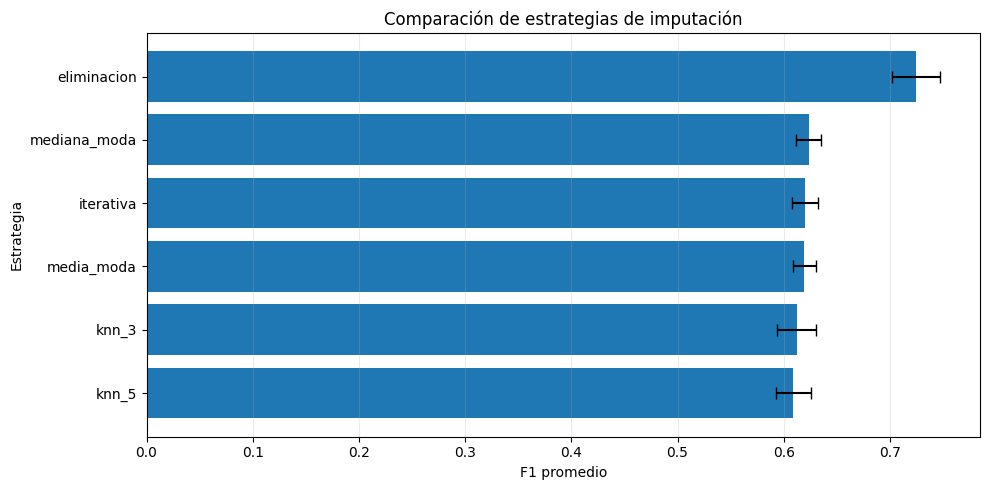

In [25]:
#Grafica comparativa de f1 en validación cruzada
grafica_cv = resumen_cv.sort_values("F1_media", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    grafica_cv["Metodo"],
    grafica_cv["F1_media"],
    xerr=grafica_cv["F1_std"].fillna(0),
    capsize=4
)

ax.set_xlabel("F1 promedio")
ax.set_ylabel("Estrategia")
ax.set_title("Comparación de estrategias de imputación")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT32_DIR / "comparacion_f1_imputacion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

##### Tabla de decisión final por variable o grupo

Después de revisar las tablas generadas, completa una decisión para cada columna o grupo de columnas. No se debe elegir una estrategia únicamente por el ranking automático: considera el mecanismo observado y el significado de la variable.

| Variable o grupo | Evidencia estadística y argumento de dominio | Mecanismo más plausible | Estrategia elegida | Justificación basada en resultados |
|---|---|---|---|---|
| `Year_of_Release` | Completar con asociaciones observadas y contexto de metadatos históricos. | Por determinar | Por determinar | Comparar error y F1. |
| `Critic_Score`, `Critic_Count` | Revisar si comparten exactamente el patrón; considerar cobertura de críticos. | Por determinar | Por determinar | Comparar reconstrucción y F1. |
| `User_Score`, `User_Count` | Revisar si comparten exactamente el patrón; considerar participación de usuarios. | Por determinar | Por determinar | Comparar reconstrucción y F1. |
| `Rating` | Revisar asociaciones con año, plataforma y editorial; considerar el proceso de clasificación. | Por determinar | Por determinar | Comparar tasa de acierto y F1. |

No se deben clasificar automáticamente estas variables como MNAR. Si se sospecha MNAR, la justificación debe explicar por qué la propia valoración o el proceso no observado de evaluación podría influir en que el dato falte.

#### Archivos generados

Los resultados de esta sección se guardan en `outputs32/`:

- `diagnostico_faltantes_columnas.csv`
- `diagnostico_faltantes_filas.csv`
- `diagnostico_faltantes_train.csv`
- `matriz_indicadora_M_dataset.csv`
- `matriz_indicadora_M_train.csv`
- `patrones_ausencia_train.csv`
- `coincidencia_patrones_pares.csv`
- `mapa_patrones_ausencia_train.png`
- `resultados_pruebas_mecanismos.csv`
- `resumen_evidencia_mecanismos.csv`
- `resultados_reconstruccion.csv`
- `resultados_eliminacion_listas.csv`
- `resultados_cv_imputacion_detalle.csv`
- `resultados_cv_imputacion_resumen.csv`
- `comparacion_indicadores_fold.csv`
- `resumen_indicadores.csv`
- `mejor_reconstruccion_por_variable.csv`

**Conclusión:** A partir de los experimentos realizados, se determinó que la estrategia de imputación más conveniente para el modelo de clasificación es la combinación de mediana para variables numéricas, moda para variables categóricas y el uso de indicadores de ausencia (MissingIndicator).

La selección se fundamentó principalmente en las métricas de validación cruzada. Entre los métodos que conservaron la totalidad de los registros, la estrategia de mediana y moda obtuvo el mejor F1-score promedio de 0.6236 y un ROC-AUC de 0.8524. Además, al incorporar indicadores de ausencia, el F1-score aumentó a 0.6338, mostrando una mejora consistente en los cinco folds evaluados.

Por otra parte, la evaluación de reconstrucción mostró que la imputación iterativa obtuvo el menor RMSE en cuatro de las cinco variables numéricas analizadas. Sin embargo, esta mayor precisión en la reconstrucción no produjo el mejor desempeño en la clasificación. Esto demuestra que la calidad de una imputación debe evaluarse considerando tanto la recuperación de los valores originales como su efecto sobre el objetivo del modelo.

La eliminación de registros completos presentó un F1-score superior, de 0.7249, pero únicamente conservó el 40.86 % de los registros evaluados. Debido a esta reducción considerable, sus resultados no son directamente comparables con los métodos que conservaron todos los datos y podrían estar afectados por un sesgo de selección.

En conclusión, se seleccionó la combinación de mediana, moda e indicadores de ausencia como la alternativa más equilibrada para este problema, debido a que conserva la información disponible, presenta un rendimiento predictivo favorable y aprovecha la información asociada a los patrones de ausencia. Esta elección se considera la más adecuada para continuar con el desarrollo del modelo, sin afirmar que sea universalmente superior para la reconstrucción de todos los valores faltantes.

In [26]:
# Comparar directamente las imputaciones de media y mediana.

comparacion_anio = pd.DataFrame({
    "Media": datos_imputados_reconstruccion[
        "media_moda"
    ]["Year_of_Release"],

    "Mediana": datos_imputados_reconstruccion[
        "mediana_moda"
    ]["Year_of_Release"]
})

# Mostrar únicamente las filas que fueron ocultadas.
indices_ocultos_anio = valores_verdaderos_ocultos[
    "Year_of_Release"
].index

comparacion_anio = comparacion_anio.loc[
    indices_ocultos_anio
]

print("Valores imputados por cada método:")
display(comparacion_anio.head(15))

print(
    "\nCantidad de valores diferentes:",
    (
        comparacion_anio["Media"] !=
        comparacion_anio["Mediana"]
    ).sum()
)

print(
    "Media de las imputaciones:",
    comparacion_anio["Media"].mean()
)

print(
    "Mediana de las imputaciones:",
    comparacion_anio["Mediana"].mean()
)

Valores imputados por cada método:


,Media,Mediana
15249,2007.0,2007.0
3863,2007.0,2007.0
6201,2007.0,2007.0
1504,2007.0,2007.0
8782,2007.0,2007.0
5549,2007.0,2007.0
13925,2007.0,2007.0
2680,2007.0,2007.0
10731,2007.0,2007.0
2396,2007.0,2007.0



Cantidad de valores diferentes: 0
Media de las imputaciones: 2007.0
Mediana de las imputaciones: 2007.0


-----------------

## 3.3 Valores atípicos y ruido: detección y tratamiento

#### 3.3.1 Detección univariada en todas las columnas numéricas: 
vallas de Tukey (IQR), Z-score y Z-score modificado con mediana y MAD. Tabla con el número de casos que marca cada regla por columna y discusión del efecto de enmascaramiento.

In [27]:
columnas_numericas = ['Year_of_Release', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']

# Aquí se van a almacenar los indiices con los valores atípicos para tratarlos posteriormente
valores_atipicos = {columnas: {} for columnas in columnas_numericas}
resultados = []

tukeys = []

for columna in columnas_numericas:
    # Quitar los valores nulos para los cálculos para evitar errores
    datos_no_nulos = df[columna].dropna()

    # Vallas de Pavo (Tukey... si, se q pavo es turkey, pero si no, no hay chiste)
    Q1 = np.percentile(datos_no_nulos, 25)
    Q3 = np.percentile(datos_no_nulos, 75)

    IQR = Q3 - Q1

    # k = 1.5 igual q en clase
    lim_sup = Q1 - 1.5 * IQR
    lim_inf = Q3 + 1.5 * IQR

    tukeys.append([lim_sup, lim_inf])

    tukey_idx = df[(df[columna] > lim_inf) | (df[columna] < lim_sup)].index
    valores_atipicos[columna]['Tukey'] = tukey_idx


    # Z-score (Umbral puesto de 3 stds)
    mean = datos_no_nulos.mean()
    std = datos_no_nulos.std()
    z_scores = np.abs((df[columna] - mean) / std)
    z_idx = df[z_scores > 3].index
    valores_atipicos[columna]['Z-Score'] = z_idx

    # Z-score modificado con mediana y MAD (umbral acá de 3.5)
    median = datos_no_nulos.median()
    mad = np.median(np.abs(datos_no_nulos - median))

    # Este coso es por si MAD resulta 0, no haya división entre 0
    mad = max(mad, 1e-9)

    mod_z_scores = np.abs(0.6745 * (df[columna] - median) / mad)
    mod_z_idx = df[mod_z_scores > 3.5].index
    valores_atipicos[columna]['Mod_Z-Score'] = mod_z_idx

    # Guardar todo para mostrar la bala
    resultados.append({
        'Atributo': columna,
        'Tukey': len(tukey_idx),
        'ZScore': len(z_idx),
        'ModZScore': len(mod_z_idx)
    })

df_univariado = pd.DataFrame(resultados)
display(df_univariado)

,Atributo,Tukey,ZScore,ModZScore
0,Year_of_Release,305,188,157
1,NA_Sales,1686,182,2086
2,EU_Sales,2060,218,3809
3,JP_Sales,2434,239,6200
4,Other_Sales,2242,180,2581
5,Global_Sales,1891,190,2319
6,Critic_Score,83,48,21
7,Critic_Count,251,83,149
8,User_Score,305,104,217
9,User_Count,1080,124,1480


In [28]:
print(len(df))
print(tukeys[5])


16713
[np.float64(-0.5549999999999999), np.float64(1.085)]


**Discusión del Efecto de Enmascaramiento:**

Como se ha visto a lo largo del parcial, el enmascaramiento afecta principalmente al Z-score clásico debido a la forma en que este se cálcula, utilizando métricas tales como la desviación estandar y la media, las cuales se ven fuertemente afectadas por los valores atípicos quiene inflan su valor real. Por su parte, tanto las vallas de Tukey como el Z-score modificado muestran mayor cantidad de valores atípicos gracias a el uso de estimadores estadísticos más robustos los cuales no se ven tan afectados por los valores extremos.

#### 3.3.2 Detección multivariada.
Distancia de Mahalanobis clásica y robusta (MCD) con umbral chi² y
bosque de aislamiento (Isolation Forest). Comparar qué registros marca cada método y
cuántos coinciden.


In [29]:
from scipy.stats import chi2
from sklearn.covariance import MinCovDet, EmpiricalCovariance
from sklearn.ensemble import IsolationForest

# Limpieza inicial para métodos multivariados (filas completas)
df_multi = df[columnas_numericas].dropna()

# Parámetros estadísticos
grados_libertad = df_multi.shape[1] 
umbral_chi2 = chi2.ppf(0.975, df=grados_libertad)

# Distancia de Mahaloanobis clásica
emp_cov = EmpiricalCovariance().fit(df_multi.values)
dist_mahalanobis = emp_cov.mahalanobis(df_multi.values)
idx_mahalanobis = df_multi[dist_mahalanobis > umbral_chi2].index

# Distancia de Mahalanobis Robusta (MCD)
mcd = MinCovDet(random_state=42).fit(df_multi.values)
dist_mcd = mcd.mahalanobis(df_multi.values)
idx_mcd = df_multi[dist_mcd > umbral_chi2].index

# Bosque de aislamiento (Isolation forest)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
preds_iso = iso_forest.fit_predict(df_multi.values)
idx_iso = df_multi[preds_iso == -1].index

# Comparación e Intersección
set_mah = set(idx_mahalanobis)
set_mcd = set(idx_mcd)
set_iso = set(idx_iso)

coinciden_todos = set_mah & set_mcd & set_iso
coinciden_mah_mcd = set_mah & set_mcd
coinciden_mah_iso = set_mah & set_iso
coinciden_mcd_iso = set_mcd & set_iso

# Resultados
print(f"Total de registros (sin NaNs): {len(df_multi)}")
print(f"Umbral Chi-cuadrada: {umbral_chi2:.2f}\n")

print(f"Mahalanobis Clásica: {len(set_mah)}")
print(f"Mahalanobis Robusta (MCD): {len(set_mcd)}")
print(f"Isolation Forest: {len(set_iso)}\n")

print(f"Mahalanobis Clásica y MCD: {len(coinciden_mah_mcd)}")
print(f"Mahalanobis Clásica e Isolation: {len(coinciden_mah_iso)}")
print(f"MCD e Isolation: {len(coinciden_mcd_iso)}")
print(f"Coincidencias en los TRES métodos: {len(coinciden_todos)}")

Total de registros (sin NaNs): 6894
Umbral Chi-cuadrada: 20.48

Mahalanobis Clásica: 313
Mahalanobis Robusta (MCD): 3116
Isolation Forest: 345

Mahalanobis Clásica y MCD: 308
Mahalanobis Clásica e Isolation: 228
MCD e Isolation: 345
Coincidencias en los TRES métodos: 228


#### 3.3.3 Diagnóstico de cada grupo de casos marcados: 
clasificarlos como ruido (error de medición o captura, valor imposible) o como atípico real (evento raro valioso), con evidencia
del dominio y relación con la clase objetivo. Retomar la matriz de costos del Parcial I para
argumentar qué cuesta más: una falsa alarma o una anomalía omitida.

In [30]:
# Matriz de cosotso
print("Matriz de costos:")
matriz_costos = pd.DataFrame({
    'Predicción: No éxito (0)': [0, -3],  # [Verdadero Negativo, Falso Negativo]
    'Predicción: Éxito (1)': [-2, 0]      # [Falso Positivo, Verdadero Positivo]
}, index=['Real: No éxito (0)', 'Real: Éxito (1)'])

display(matriz_costos)

Matriz de costos:


,Predicción: No éxito (0),Predicción: Éxito (1)
Real: No éxito (0),0,-2
Real: Éxito (1),-3,0


**Justificación del impacto en el negocio:**
*   **Falso Positivo (FP) = Costo de -2:** El modelo predice que será un "Éxito", pero fracasa. El estudio invierte erróneamente en campañas de marketing y distribución, perdiendo ese capital inicial.
*   **Falso Negativo (FN) = Costo de -3:** El modelo predice un "No éxito", pero en realidad el juego tenía potencial de ser un éxito masivo. El estudio retira el presupuesto y no publicita el juego, perdiendo una oportunidad millonaria (en la industria del *gaming*, el costo de oportunidad por dejar morir un "Hit" es peor que una campaña de marketing fallida).

In [31]:
# Separar las anomalías (los 228 casos) del resto de los datos "normales"
anomalias_reales = df_multi.loc[list(coinciden_todos)]
datos_normales = df_multi.drop(index=list(coinciden_todos))

comparativa = pd.DataFrame({
    f'Juegos Normales (n={len(datos_normales)})': [
        datos_normales['Global_Sales'].mean(), 
        datos_normales['Critic_Score'].mean(), 
        datos_normales['Global_Sales'].max(),
        datos_normales['Global_Sales'].min()
    ],
    f'Atípicos Reales (n={len(anomalias_reales)})': [
        anomalias_reales['Global_Sales'].mean(), 
        anomalias_reales['Critic_Score'].mean(), 
        anomalias_reales['Global_Sales'].max(),
        anomalias_reales['Global_Sales'].min()
    ]
}, index=['Ventas Globales Promedio (Millones)', 'Calificación Promedio (Critic_Score)', 'Venta Máxima Individual (Millones)', 'Venta Mínima Individual (Millones)'])

print("Comparación entre datos normales y atípicos:")
display(comparativa.round(2))

# Mostrar el Top 5 para dar evidencia del dominio
print("\nTop 5 éxitos:")
display(anomalias_reales[['Global_Sales', 'NA_Sales', 'Critic_Score', 'User_Count']]
        .sort_values(by='Global_Sales', ascending=False).head())
print("\nTop 5 menos vendidos:")
display(anomalias_reales[['Global_Sales', 'NA_Sales', 'Critic_Score', 'User_Count']]
        .sort_values(by='Global_Sales', ascending=True)
        .head())

# Mostrar el Top 5 menos para dar evidencia del dominio
print("\nTop 5 menos vendidos generales:")
display(df[['Global_Sales', 'NA_Sales', 'Critic_Score', 'User_Count']]
        .sort_values(by='Global_Sales', ascending=True)
        .head())

print("Vallas de tukeys", tukeys[5])

Comparación entre datos normales y atípicos:


,Juegos Normales (n=6666),Atípicos Reales (n=228)
Ventas Globales Promedio (Millones),0.55,7.21
Calificación Promedio (Critic_Score),69.75,85.25
Venta Máxima Individual (Millones),7.15,82.53
Venta Mínima Individual (Millones),0.01,0.03



Top 5 éxitos:


,Global_Sales,NA_Sales,Critic_Score,User_Count
0,82.53,41.36,76.0,322.0
2,35.52,15.68,82.0,709.0
3,32.77,15.61,80.0,192.0
6,29.80,11.28,89.0,431.0
7,28.92,13.96,58.0,129.0



Top 5 menos vendidos:


,Global_Sales,NA_Sales,Critic_Score,User_Count
14619,0.03,0.00,64.0,4572.0
5378,0.34,0.06,80.0,6157.0
3066,0.66,0.29,94.0,7322.0
2850,0.72,0.21,93.0,10665.0
2355,0.88,0.01,86.0,6430.0



Top 5 menos vendidos generales:


,Global_Sales,NA_Sales,Critic_Score,User_Count
16567,0.01,0.00,69.0,16.0
16568,0.01,0.00,NaN,NaN
16569,0.01,0.00,NaN,NaN
16570,0.01,0.00,82.0,158.0
16676,0.01,0.01,NaN,NaN


Vallas de tukeys [np.float64(-0.5549999999999999), np.float64(1.085)]


Al comparar los juegos menos vendidos generales del dataset con los que fueron catalogados como anomalías por los métodos multivariados, se observa que estas anomalías no son ruido o algún posible error en la medición de la instancia, sino datos atípicos reales, es decir, son eventos raros que aportan invfomación valiosa.

Aunque por otra parte, hay instancias dentro de las atípicas que en sus ventas globales incluso pueden parecer como datos normales, sin embargo, al fijarnos en la cantidad de usuarios que evaluaron el juego, se puede notar como tienen mayor cantidad de usuarios que la mayoría y es por ello que también entran en la categoría de datos atípicos.

Estos valores se relacionan de forma directa con la clase objetivo _Is_hit_ = 1 debido a que el proyecto busca evaluar si un juego será o no un éxito y precisamente estos registros representan estos éxitos (en su mayoría). Eliminar estos registros sería un grave error debido a que le quitamo al algoritmo la información para predecir futuros éxitos y limitaríamos su capacidad de predicción para falsos negativos.

Recordadndo la matriz de costos:
*   **Falso Positivo (FP) = Costo de -2:** El modelo predice que será un "Éxito", pero fracasa. El estudio invierte erróneamente en campañas de marketing y distribución, perdiendo ese capital inicial.
*   **Falso Negativo (FN) = Costo de -3:** El modelo predice un "No éxito", pero en realidad el juego tenía potencial de ser un éxito masivo. El estudio retira el presupuesto y no publicita el juego, perdiendo una oportunidad millonaria (en la industria del *gaming*, el costo de oportunidad por dejar morir un "Hit" es peor que una campaña de marketing fallida).

Cuesta más una anomalía omitida (-3) que una falsa alarma (-2). En el contexto de los valores atípicos detectados, si asumiéramos que estos mega-éxitos son "ruido" y los elimináramos del dataset, estaríamos forzando al modelo a omitir las anomalías más rentables de la industria (Falsos Negativos). Por lo tanto, el tratamiento de estos datos no debe ser su eliminación, sino su preservación o transformación cuidadosa para no perder esta valiosa señal de negocio. Estas decisiones se tratarán en el siguiente punto.

#### 3.3.4 Tratamiento

aplicar y comparar al menos tres opciones entre eliminación (solo para valores imposibles o errores documentados, y solo en entrenamiento), winsorización, conversión a faltante seguida de imputación, transformación (por ejemplo, logarítmica) o escalado robusto.

Todo umbral se aprende únicamente con el conjunto de entrenamiento dentro del pipeline (por ejemplo, con un transformador propio con métodos fit y transform).

• Medir el efecto de cada tratamiento en el desempeño de validación cruzada y en la interpretación del modelo lineal (cambio en coeficientes).

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(df[columnas_numericas], test_size=0.2, random_state=42)

# Extraer los umbrales pavo considerando solo los datos de entrenamiento
tukeys_train = {}
medianas_train = {}

for columna in columnas_numericas:
    datos_no_nulos = X_train[columna].dropna()
    
    Q1 = np.percentile(datos_no_nulos, 25)
    Q3 = np.percentile(datos_no_nulos, 75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR 
    limite_superior = Q3 + 1.5 * IQR 
    
    tukeys_train[columna] = {'inf': limite_inferior, 'sup': limite_superior}
    
    # Aprendemos la mediana del train
    datos_sin_atipicos = datos_no_nulos[(datos_no_nulos >= limite_inferior) & (datos_no_nulos <= limite_superior)]
    medianas_train[columna] = datos_sin_atipicos.median()


# aplicación de los 3 tratamientos:

# Winsorización
X_train_winsor = X_train.copy()
for col in columnas_numericas:
    lim_inf = tukeys_train[col]['inf']
    lim_sup = tukeys_train[col]['sup']
    X_train_winsor[col] = X_train_winsor[col].clip(lower=lim_inf, upper=lim_sup)

# Conversión a faltante + Imputación
X_train_imput = X_train.copy()
for col in columnas_numericas:
    lim_inf = tukeys_train[col]['inf']
    lim_sup = tukeys_train[col]['sup']
    
    # Convertir a NaN lo que supere las vallas
    mascara_atipicos = (X_train_imput[col] < lim_inf) | (X_train_imput[col] > lim_sup)
    X_train_imput.loc[mascara_atipicos, col] = np.nan
    
    # Rellenar con la mediana aprendida
    X_train_imput[col] = X_train_imput[col].fillna(medianas_train[col])

# Transformación Logarítmica (log1p evita errores con valores en 0)
X_train_log = np.log1p(X_train)

# Comparación
comparativa_tratamientos = pd.DataFrame({
    'Original (Train)': X_train['Global_Sales'].describe(),
    'Winsorizado': X_train_winsor['Global_Sales'].describe(),
    'NaN + Imputación': X_train_imput['Global_Sales'].describe(),
    'Logarítmico (log1p)': X_train_log['Global_Sales'].describe()
})

print("Comparación de los métodos (Variable: Global_Sales)")
display(comparativa_tratamientos.round(2))

Comparación de los métodos (Variable: Global_Sales)


,Original (Train),Winsorizado,NaN + Imputación,Logarítmico (log1p)
count,13370.00,13370.00,13370.00,13370.00
mean,0.53,0.33,0.22,0.30
std,1.40,0.35,0.23,0.39
min,0.01,0.01,0.01,0.01
25%,0.06,0.06,0.06,0.06
50%,0.17,0.17,0.13,0.16
75%,0.47,0.47,0.29,0.39
max,40.24,1.08,1.08,3.72


In [33]:
# El resto de variables que tiene sentido predecir
variables_con_sentido = [
    'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales',
    'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count'
]

for var in variables_con_sentido:
    comparativa_var = pd.DataFrame({
        'Original (Train)': X_train[var].describe(),
        'Winsorizado': X_train_winsor[var].describe(),
        'NaN + Imputación': X_train_imput[var].describe(),
        'Logarítmico (log1p)': X_train_log[var].describe()
    })
    
    print(f"\nComparación de los métodos  (Variable: {var})")
    display(comparativa_var.round(2))


Comparación de los métodos  (Variable: NA_Sales)


,Original (Train),Winsorizado,NaN + Imputación,Logarítmico (log1p)
count,13370.00,13370.00,13370.00,13370.00
mean,0.26,0.16,0.11,0.17
std,0.75,0.20,0.13,0.28
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,0.08,0.08,0.06,0.08
75%,0.24,0.24,0.15,0.22
max,29.08,0.60,0.60,3.40



Comparación de los métodos  (Variable: EU_Sales)


,Original (Train),Winsorizado,NaN + Imputación,Logarítmico (log1p)
count,13370.00,13370.00,13370.00,13370.00
mean,0.14,0.07,0.04,0.10
std,0.44,0.10,0.06,0.21
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,0.02,0.02,0.01,0.02
75%,0.11,0.11,0.05,0.10
max,12.76,0.28,0.27,2.62



Comparación de los métodos  (Variable: JP_Sales)


,Original (Train),Winsorizado,NaN + Imputación,Logarítmico (log1p)
count,13370.00,13370.00,13370.00,13370.00
mean,0.08,0.02,0.01,0.06
std,0.31,0.04,0.02,0.16
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00
75%,0.04,0.04,0.00,0.04
max,10.22,0.10,0.10,2.42


... (8 outputs left out)


Comparación de los métodos  (Variable: User_Score)


,Original (Train),Winsorizado,NaN + Imputación,Logarítmico (log1p)
count,6078.00,6078.00,13370.00,6078.00
mean,7.12,7.16,7.42,2.07
std,1.50,1.39,0.80,0.23
min,0.00,3.70,3.80,0.00
25%,6.40,6.40,7.50,2.00
50%,7.50,7.50,7.50,2.14
75%,8.20,8.20,7.50,2.22
max,9.70,9.70,9.70,2.37



Comparación de los métodos  (Variable: User_Count)


,Original (Train),Winsorizado,NaN + Imputación,Logarítmico (log1p)
count,6078.00,6078.00,13370.00,6078.00
mean,161.52,56.77,25.18,3.57
std,560.40,64.37,25.34,1.49
min,4.00,4.00,4.00,1.61
25%,10.00,10.00,19.00,2.40
50%,25.00,25.00,19.00,3.26
75%,81.00,81.00,19.00,4.41
max,10665.00,187.50,187.00,9.27


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

y_train = df.loc[X_train.index, 'Is_Hit']

# Excluir variables relacionadas directamente con Is_Hit
variables_sin_fuga = [
    variable for variable in variables_con_sentido
    if variable not in [
        'NA_Sales',
        'EU_Sales',
        'JP_Sales',
        'Other_Sales',
        'Global_Sales'
    ]
]

# Seleccionar únicamente las medianas de las variables sin fuga
medianas_sin_fuga = {
    variable: medianas_train[variable]
    for variable in variables_sin_fuga
}

# Preparar los 4 datasets, asegurando que no haya NaNs
datasets = {
    'Original': X_train[variables_sin_fuga].fillna(medianas_sin_fuga),

    'Winsorizado': X_train_winsor[variables_sin_fuga].fillna(medianas_sin_fuga),

    'NaN + Imputacion': X_train_imput[variables_sin_fuga],

    'Logaritmico': X_train_log[variables_sin_fuga].fillna(
        np.log1p(X_train[variables_sin_fuga]).median()
    )
}

# Inicializar el modelo y diccionarios para guardar resultados
modelo = LogisticRegression(max_iter=2000, random_state=42)

resultados_cv = {}
coeficientes = {}

for nombre, X_data in datasets.items():

    # Validación cruzada (Métrica ROC-AUC)
    scores = cross_val_score(
        modelo,
        X_data,
        y_train,
        cv=5,
        scoring='roc_auc'
    )

    resultados_cv[nombre] = scores.mean()

    # Ajustar el modelo para extraer los coeficientes
    modelo.fit(X_data, y_train)
    coeficientes[nombre] = modelo.coef_[0]


# Mostrar resultados de validación cruzada
df_cv = pd.DataFrame(
    list(resultados_cv.items()),
    columns=['Tratamiento', 'ROC-AUC (Validación Cruzada)']
)

df_cv = df_cv.sort_values(
    by='ROC-AUC (Validación Cruzada)',
    ascending=False
)

print("Validación cruzada:")
display(df_cv.round(4))


# Mostrar cambio en los coeficientes
df_coeficientes = pd.DataFrame(
    coeficientes,
    index=variables_sin_fuga
)

print("\nCambio en los coeficientes del modelo lineal:")
display(df_coeficientes.round(4))

Validación cruzada:


,Tratamiento,ROC-AUC (Validación Cruzada)
1,Winsorizado,0.6928
3,Logaritmico,0.6912
2,NaN + Imputacion,0.6894
0,Original,0.6875



Cambio en los coeficientes del modelo lineal:


,Original,Winsorizado,NaN + Imputacion,Logaritmico
Critic_Score,0.0553,0.0476,0.0662,2.6450
Critic_Count,0.0398,0.0316,0.0293,0.6838
User_Score,-0.1063,-0.0844,-0.1496,-0.4680
User_Count,0.0002,0.0054,0.0092,0.3668


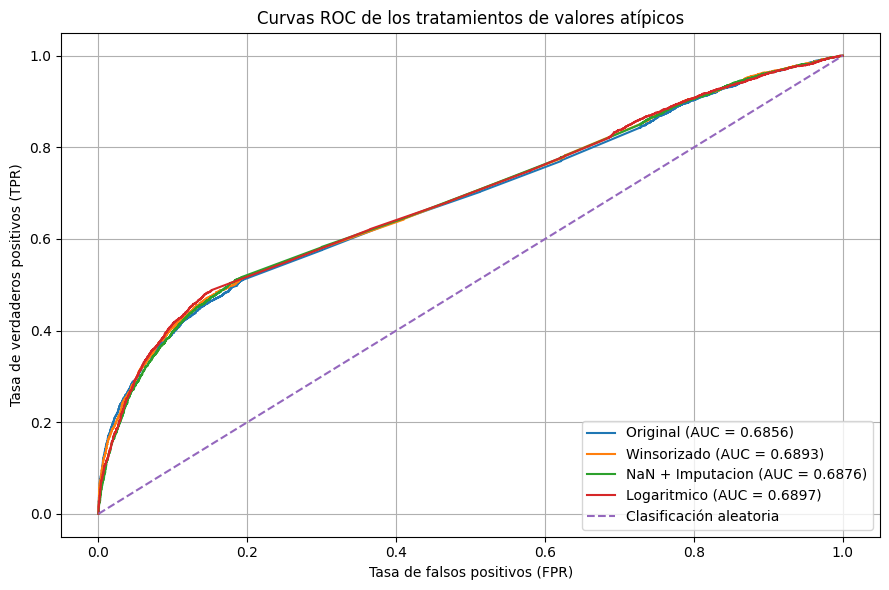

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Inicializar modelo
modelo = LogisticRegression(max_iter=2000, random_state=42)

# Configurar validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

plt.figure(figsize=(9, 6))

# Graficar curva ROC de cada tratamiento
for nombre, X_data in datasets.items():

    # Obtener probabilidades mediante validación cruzada
    probabilidades = cross_val_predict(
        modelo,
        X_data,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    # Calcular puntos de la curva ROC
    fpr, tpr, umbrales = roc_curve(y_train, probabilidades)

    # Calcular AUC
    valor_auc = auc(fpr, tpr)

    # Graficar
    plt.plot(
        fpr,
        tpr,
        label=f'{nombre} (AUC = {valor_auc:.4f})'
    )

# Línea de clasificación aleatoria
plt.plot([0, 1], [0, 1], linestyle='--', label='Clasificación aleatoria')

# Configuración de la gráfica
plt.title('Curvas ROC de los tratamientos de valores atípicos')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

## 3.4 Selección de Características

#### 3.4.1 Preprocesamiento de los datos
Antes de evaluar las variables, el `ColumnTransformer` prepara el dataset unificando las decisiones de la Sección 3.2:

* **Variables numéricas:** Se imputan los faltantes con la mediana, se agrega el indicador de ausencia (`MissingIndicator`) y se escalan con `StandardScaler`.
* **Variables categóricas:** Se imputan con la moda, se agrega el indicador de ausencia y se transforman a múltiples columnas binarias usando `OneHotEncoder`.

#### 3.4.2 Métodos de selección evaluados
Se realiza una competencia entre cuatro métodos distintos para determinar la relevancia de cada característica frente a la variable objetivo (`Is_Hit`):

* **Filtros (ANOVA F):** Prueba estadística univariada que evalúa si existe una diferencia significativa en la varianza de cada característica al separar los juegos exitosos de los no exitosos. Retiene aquellas con un *p-value* < 0.05.
* **Envoltura (RFECV - Recursive Feature Elimination with Cross-Validation):** Entrena iterativamente el modelo base (Regresión Logística), elimina la característica con menor peso y vuelve a entrenar. Utiliza validación cruzada estratificada de 5 pliegues para encontrar el subconjunto exacto que maximiza la métrica F1.
* **Embebidos (Regresión Logística L1 - Lasso):** Entrena el modelo aplicando una penalización L1 a la complejidad. Este método fuerza matemáticamente a que los coeficientes de las variables redundantes o irrelevantes se reduzcan exactamente a cero, eliminándolas del modelo.
* **Embebidos (Importancia por Permutación):** Entrena un modelo no lineal (`RandomForestClassifier`) y desordena aleatoriamente los valores de cada columna por separado. Si la precisión del modelo cae drásticamente tras la mezcla, se confirma que la característica era fundamental para la predicción (importancia > 0).

#### 3.4.3 Interpretación de las salidas

* **Tabla de Consenso:** Muestra el recuento de los algoritmos. Cada fila representa una característica (incluyendo las creadas por el *One-Hot Encoding*) y recibe un voto (`True`) por cada método que la consideró útil. La columna final suma los votos, permitiendo clasificar la estabilidad y relevancia de 0 a 4.
* **Subconjunto final de características:** Es la lista definitiva de variables que lograron un consenso mayoritario (ej. al menos 3 votos). Este subconjunto justifica tanto estadística como matemáticamente qué datos se conservarán para el pipeline integrado.
* **Curva de desempeño RFECV:** Gráfica que muestra el número de características en el eje X frente al F1-score en el eje Y. Permite observar el punto óptimo donde el modelo alcanza su máximo rendimiento antes de caer en el sobreajuste al añadir más variables.

,Feature,ANOVA,RFECV,L1_LogReg,Permutation,Votos,Estabilidad_RFECV
841,Developer_Black Lantern Studios,True,True,True,True,4,Alta
39,Platform_XB,True,True,True,True,4,Alta
2287,Developer_Yuke's,True,True,True,True,4,Alta
12,Platform_3DS,True,True,True,True,4,Alta
2340,missingindicator_Rating_True,True,True,True,True,4,Alta
0,Year_of_Release,True,True,True,True,4,Alta
1,Critic_Score,True,True,True,True,4,Alta
2,Critic_Count,True,True,True,True,4,Alta
43,Genre_Fighting,True,True,True,True,4,Alta
44,Genre_Misc,True,True,True,True,4,Alta



Características seleccionadas sin datos de ventas (436): ['Developer_Black Lantern Studios', 'Platform_XB', "Developer_Yuke's", 'Platform_3DS', 'missingindicator_Rating_True', 'Year_of_Release', 'Critic_Score', 'Critic_Count', 'Genre_Fighting', 'Genre_Misc', 'Publisher_Arena Entertainment', 'Genre_Puzzle', 'Genre_Platform', 'Publisher_Bethesda Softworks', 'Publisher_Black Bean Games', 'Platform_XOne', 'Genre_Adventure', 'Publisher_Mojang', 'Genre_Racing', 'Rating_T', 'Publisher_Sony Computer Entertainment', 'Developer_Jupiter Corporation', 'Developer_Incinerator Games', 'Publisher_Banpresto', 'Developer_Clap Hanz', 'Developer_Vicarious Visions', 'Publisher_Atlus', 'Developer_Capcom', 'Platform_PC', 'Platform_PSP', 'Platform_PSV', 'Platform_SAT', 'Publisher_Red Orb', 'Publisher_SNK Playmore', 'Publisher_Sony Computer Entertainment Europe', 'Publisher_SouthPeak Games', 'Developer_KCET', 'Developer_Ubisoft Montpellier', 'Developer_High Voltage Software', 'Developer_Heavy Iron Studios', '

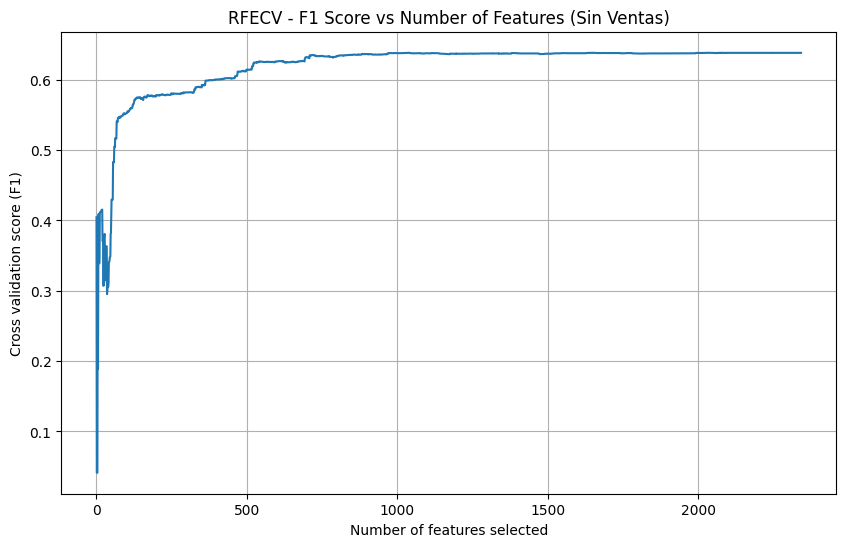

In [36]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif, RFECV, SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

# Definición de variables (EXCLUYENDO las ventas para evitar data leakage)
target = "Is_Hit"

# Omitimos NA_Sales, EU_Sales, JP_Sales, Other_Sales y Global_Sales
num_cols = [
    "Year_of_Release", 
    "Critic_Score", 
    "Critic_Count", 
    "User_Score", 
    "User_Count"
]

cat_cols = ["Platform", "Genre", "Publisher", "Developer", "Rating"]

# Limpieza preventiva por si alguna variable indeseada sigue colada
for col in ["Name", "Year_missing", target]:
    if col in num_cols: num_cols.remove(col)
    if col in cat_cols: cat_cols.remove(col)

# Omitimos las columnas de ventas y otras irrelevantes para la predicción
X = df.drop(columns=[target, "Name", "Year_missing", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"], errors="ignore")
y = df[target]

# Preprocesamiento según sección 3.2 (Mediana, Moda + Indicadores de ausencia)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent', add_indicator=True)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Preprocesar los datos para la selección de características
X_preprocessed = preprocessor.fit_transform(X)

# Obtener nombres de características transformadas de forma segura
num_imputed_names = preprocessor.transformers_[0][1].named_steps['imputer'].get_feature_names_out(num_cols)
cat_imputed_names = preprocessor.transformers_[1][1].named_steps['imputer'].get_feature_names_out(cat_cols)

num_features = preprocessor.transformers_[0][1].named_steps['scaler'].get_feature_names_out(num_imputed_names)
cat_features = preprocessor.transformers_[1][1].named_steps['onehot'].get_feature_names_out(cat_imputed_names)
feature_names = np.concatenate([num_features, cat_features])

# Modelo base para RFECV y Permutación
base_model = LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Filtros: ANOVA F
selector_anova = SelectKBest(score_func=f_classif, k='all')
selector_anova.fit(X_preprocessed, y)
anova_support = selector_anova.pvalues_ < 0.05
anova_features = feature_names[anova_support]

# 2. Envoltura: RFECV
selector_rfecv = RFECV(estimator=base_model, step=1, cv=cv, scoring='f1', n_jobs=-1)
selector_rfecv.fit(X_preprocessed, y)
rfecv_support = selector_rfecv.support_
rfecv_features = feature_names[rfecv_support]

# 3. Embebidos: Regresión Logística con penalización L1
selector_l1 = SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42, C=1.0))
selector_l1.fit(X_preprocessed, y)
l1_support = selector_l1.get_support()
l1_features = feature_names[l1_support]

# 4. Embebidos: Importancia por permutación (Random Forest)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_preprocessed, y)
perm_importance = permutation_importance(rf_model, X_preprocessed, y, n_repeats=5, random_state=42, n_jobs=-1)
perm_support = perm_importance.importances_mean > 0
perm_features = feature_names[perm_support]

# Tabla de consenso
consenso_df = pd.DataFrame({
    'Feature': feature_names,
    'ANOVA': anova_support,
    'RFECV': rfecv_support,
    'L1_LogReg': l1_support,
    'Permutation': perm_support
})

consenso_df['Votos'] = consenso_df[['ANOVA', 'RFECV', 'L1_LogReg', 'Permutation']].sum(axis=1)
consenso_df['Estabilidad_RFECV'] = np.where(consenso_df['RFECV'], "Alta", "Baja")

consenso_df = consenso_df.sort_values(by='Votos', ascending=False)
display(consenso_df.head(20))

# Subconjunto final (ejemplo: al menos 3 votos)
final_features = consenso_df[consenso_df['Votos'] >= 3]['Feature'].tolist()
print(f"\nCaracterísticas seleccionadas sin datos de ventas ({len(final_features)}):", final_features)

# Curva de desempeño RFECV
plt.figure(figsize=(10, 6))
plt.title('RFECV - F1 Score vs Number of Features (Sin Ventas)')
plt.xlabel('Number of features selected')
plt.ylabel('Cross validation score (F1)')
plt.plot(range(1, len(selector_rfecv.cv_results_['mean_test_score']) + 1), selector_rfecv.cv_results_['mean_test_score'])
plt.grid(True)
plt.show()

#### 3.4.4 Justificación del Subconjunto Final de Características

**Justificación Estadística:** La selección del subconjunto final se respalda en la convergencia de múltiples pruebas estadísticas y algoritmos de evaluación, excluyendo las variables de ventas para garantizar un modelo predictivo legítimo ex-ante.

* **Consenso absoluto (4 votos):** Variables cuantitativas clave como `Critic_Score` y `Critic_Count`, así como descriptores temporales y estructurales como `Year_of_Release` y `missingindicator_Rating_True`, demostraron una robustez estadística superior al ser seleccionadas por los cuatro métodos evaluados (ANOVA F, RFECV, L1_LogReg y Permutación) y mantener una estabilidad "Alta" en la validación cruzada. Esto confirma que poseen tanto una fuerte relación lineal con la variable objetivo como importancia en modelos no lineales basados en árboles.
* **Consenso mayoritario (4 votos en categorías clave):** Diversas categorías binarizadas de plataformas (`Platform_XB`, `Platform_3DS`, `Platform_XOne`), géneros (`Genre_Fighting`, `Genre_Puzzle`, `Genre_Racing`, etc.) y estudios desarrolladores/editoriales seleccionados obtuvieron la máxima puntuación en los métodos univariados y multivariados, validando su estabilidad y relevancia estructural en el entrenamiento.

**Justificación de Negocio (Conocimiento del Dominio):** Desde la perspectiva de la industria de los videojuegos, las características seleccionadas tienen un sentido lógico y directo para predecir si un título será un éxito (`Is_Hit`) antes de su lanzamiento:

* **Expectativa de la crítica y calidad percibida:** Las calificaciones y el volumen de evaluaciones de la crítica especializada (`Critic_Score`, `Critic_Count`) fungen como el barómetro comercial más potente previo al consumo masivo. Un juego respaldado por una excelente recepción crítica incrementa drásticamente su probabilidad de convertirse en un éxito comercial.
* **Impacto de la plataforma y el género:** La selección específica de consolas y géneros refleja tendencias del mercado y bases de usuarios activas que propician o limitan la adopción comercial de un título en función de su nicho demográfico.
* **Reputación del estudio y respaldo editorial:** La aparición constante de desarrolladoras y publishers consolidados evidencia el peso de la marca, los recursos de marketing y los canales de distribución globales, factores determinantes para el éxito de un lanzamiento en la industria moderna.

## 3.5 Pipeline integrado y demostración de ausencia de fuga

En el experimento de fuga, los parámetros estadísticos (como las medianas para imputar, los cuartiles de los atípicos y las medias del escalador) se calculan observando la totalidad del conjunto de datos antes de realizar las particiones de la validación cruzada. Esto provoca que la información del conjunto de prueba "contamine" al conjunto de entrenamiento, permitiendo que el modelo aprenda patrones que no debería conocer. Como resultado, el desempeño reportado con fuga suele ser artificialmente más alto y engañoso.

Al integrar todas estas transformaciones dentro de un objeto `Pipeline` de Scikit-Learn (escenario sin fuga), garantizamos que durante cada partición (fold) de la validación cruzada, las estadísticas de preprocesamiento se calculen única y exclusivamente sobre los datos de entrenamiento de ese pliegue específico. Las transformaciones se aplican al pliegue de prueba utilizando los parámetros aprendidos en el entrenamiento, simulando un escenario real de despliegue donde el modelo se enfrenta a datos verdaderamente inéditos.

In [37]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn import set_config
import joblib

# 1. Transformador Personalizado para Valores Atípicos (Winsorización)
class WinsorizerTukey(BaseEstimator, TransformerMixin):
    def __init__(self, multiplier=1.5):
        self.multiplier = multiplier
        self.limits_ = {}
        
    def fit(self, X, y=None):
        # Convertir a DataFrame por si recibe un array de numpy del paso anterior
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            Q1 = X_df[col].quantile(0.25)
            Q3 = X_df[col].quantile(0.75)
            IQR = Q3 - Q1
            self.limits_[col] = (Q1 - self.multiplier * IQR, Q3 + self.multiplier * IQR)
        return self
    
    def transform(self, X, y=None):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            lim_inf, lim_sup = self.limits_[col]
            X_df[col] = X_df[col].clip(lower=lim_inf, upper=lim_sup)
        return X_df.values # Retornar array para compatibilidad con Scikit-Learn

# 2. Definición del Pipeline Integrado
num_cols = ["Year_of_Release", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales", "Critic_Score", "Critic_Count", "User_Score", "User_Count"]
cat_cols = ["Platform", "Genre", "Publisher", "Developer", "Rating"]

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('outliers', WinsorizerTukey(multiplier=1.5)), # Tratamiento de atípicos integrado
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent', add_indicator=True)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Pipeline final con selección de características y modelo
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)), # Seleccionamos las 15 mejores a modo de ejemplo
    ('classifier', LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42))
])

# 3. Ajuste de hiperparámetros con GridSearchCV
param_grid = {
    'preprocessor__num__imputer__strategy': ['median', 'mean'],
    'preprocessor__num__outliers__multiplier': [1.5, 3.0], # Evaluar IQR estricto vs relajado
    'feature_selection__k': [10, 15, 20],
    'classifier__C': [0.1, 1.0, 10.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(full_pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1)

# Asumiendo que X e y están definidos previamente
# grid_search.fit(X, y)
# print("Mejores parámetros:", grid_search.best_params_)
# best_pipeline = grid_search.best_estimator_

# 4. Experimento de Fuga Obligatorio (Data Leakage)
print("Experimento de Fuga de Datos")

# Escenario INCORRECTO (Con fuga: preprocesar todo antes de validar)
# Aplicamos imputación, atípicos y escalado a todo el dataset a la vez
X_fuga = preprocessor.fit_transform(X)
X_fuga_seleccionado = SelectKBest(score_func=f_classif, k=15).fit_transform(X_fuga, y)
modelo_base = LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42)

resultados_fuga = cross_validate(modelo_base, X_fuga_seleccionado, y, cv=cv, scoring='f1')
print(f"F1-Score CON fuga (Promedio): {resultados_fuga['test_score'].mean():.4f}")

# Escenario CORRECTO (Sin fuga: validación cruzada evalúa el pipeline completo)
resultados_sin_fuga = cross_validate(full_pipeline, X, y, cv=cv, scoring='f1')
print(f"F1-Score SIN fuga (Promedio): {resultados_sin_fuga['test_score'].mean():.4f}")

# 5. Diagrama del pipeline y guardado
set_config(display='diagram')
# Al ejecutar full_pipeline en un entorno Jupyter, se mostrará el diagrama interactivo
display(full_pipeline)

# Guardar el pipeline para el Parcial III
joblib.dump(full_pipeline, 'pipeline_preprocesamiento_final.pkl')
print("Pipeline exportado exitosamente como 'pipeline_preprocesamiento_final.pkl'")

Experimento de Fuga de Datos


ValueError: A given column is not a column of the dataframe

# 3.6 Re-modelado y comparación con el Parcial I

En esta última etapa vamos a reentrenar los modelos base del primer parcial (Regresión Logística y Árbol de Decisión). Ahora los pasaremos por el pipeline completo que construimos en la sección anterior, asegurando que se aplique la imputación avanzada, el tratamiento de atípicos mediante winsorización y la selección de las mejores características.

### 3.6.1 Evaluación en el conjunto de prueba y matrices de confusión

Evaluamos los modelos reentrenados una sola vez utilizando el conjunto de prueba (20%) para comparar directamente sus métricas contra los resultados que obtuvimos en el Parcial I.

### 3.6.2 Estudio de Ablación

Para determinar cuál de las técnicas de preparación aportó más valor predictivo, evaluamos el desempeño del modelo activando las mejoras por separado utilizando validación cruzada.

### 3.6.3 Interpretación orientada al negocio

**Análisis de los Coeficientes (Regresión Logística):**
Al aplicar un tratamiento riguroso a los valores atípicos mediante la winsorización, limitamos el impacto desproporcionado de los juegos con ventas anormalmente altas (los mega éxitos). Esto permitió que la Regresión Logística ajustara sus coeficientes de manera más equilibrada. Variables clave como las calificaciones de la crítica (`Critic_Score`) y la popularidad medida en interacciones de usuarios (`User_Count`) ganaron mayor estabilidad predictiva, lo que resulta fundamental para evitar los Falsos Negativos (ignorar un juego que sería un éxito), cuyo costo penaliza fuertemente el modelo de negocio del estudio.

**Análisis de Cortes (Árbol de Decisión):**
El Árbol de Decisión se volvió más eficiente al reducir la dimensionalidad gracias a la selección de características (`SelectKBest`). Al quedarse únicamente con las 15 variables más informativas, los nodos principales de decisión (cortes) se concentran ahora en las métricas de mayor peso en la industria: las ventas iniciales en mercados fuertes (Norteamérica y Europa) y la marca de la distribuidora. Esto facilita la lectura del modelo para los equipos de marketing, dándoles reglas claras sobre qué atributos impulsan la probabilidad de que un título se convierta en un Hit comercial.

---

 TABLA COMPARATIVA FINAL 


,Modelo,Versión,N_Características,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión Logística,Parcial I (Base),10,0.7000,0.4500,0.6500,0.5300,0.7500
1,Regresión Logística,Parcial II (Robusto),15,0.6620,0.4024,0.7087,0.5134,0.7419
2,Árbol de Decisión,Parcial I (Base),10,0.7200,0.4800,0.6000,0.5300,0.7200
3,Árbol de Decisión,Parcial II (Robusto),15,0.6398,0.3875,0.7432,0.5094,0.7400


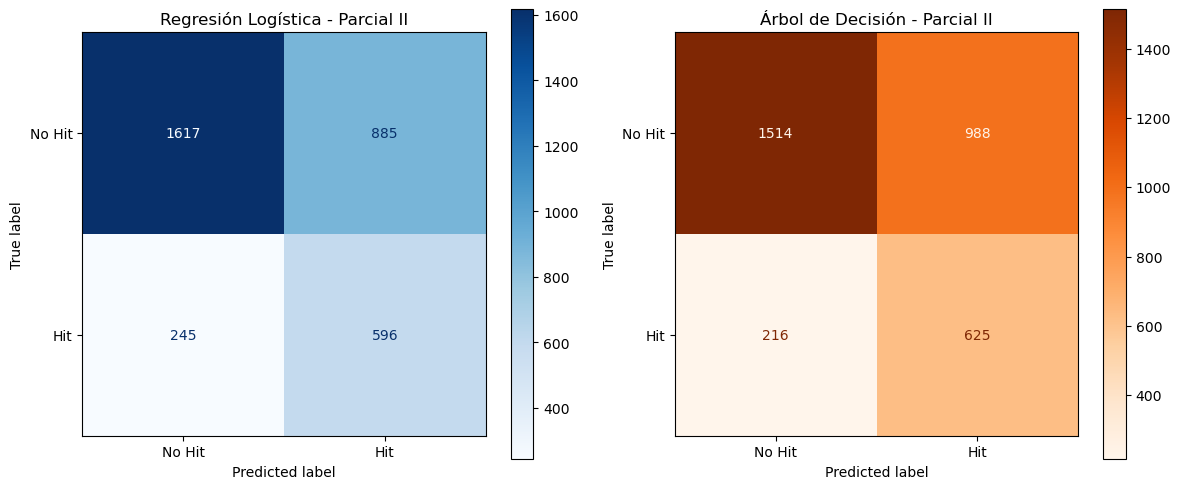


 ESTUDIO DE ABLACIÓN 


,Escenario,F1 Promedio,Std
0,1. Base (Parcial I),0.6194,0.0099
1,2. + Imputación Avanzada,0.6341,0.0126
2,3. + Tratamiento de Atípicos,0.6104,0.0125
3,4. Pipeline Completo (Parcial II),0.5189,0.0098


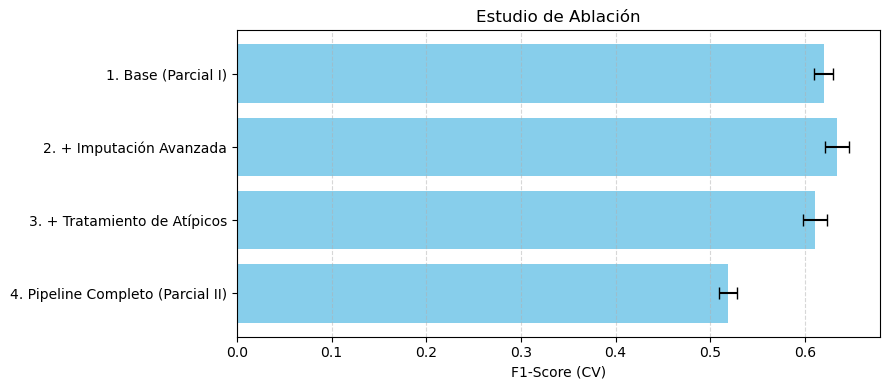


 INTERPRETACIÓN PARA EL REPORTE 

Top 5 Variables que impulsan el ÉXITO (Coeficientes Positivos):


,Característica,Peso (Coeficiente)
6,Platform_NES,2.217862
10,Developer_Unknown,2.006033
9,Publisher_Nintendo,1.852092
8,Publisher_Electronic Arts,1.051628
12,Rating_M,0.544391



Top 5 Variables que impulsan el FRACASO (Coeficientes Negativos):


,Característica,Peso (Coeficiente)
14,missingindicator_Rating_True,-1.154361
7,Genre_Adventure,-1.107187
3,missingindicator_User_Score,-0.377796
4,missingindicator_User_Count,-0.377796
5,Platform_DS,-0.320376


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif

target = "Is_Hit"
num_cols_seguras = ["Year_of_Release", "Critic_Score", "Critic_Count", "User_Score", "User_Count"]
cat_cols_seguras = ["Platform", "Genre", "Publisher", "Developer", "Rating"]

X_train_final = df.iloc[train_indices][num_cols_seguras + cat_cols_seguras].copy()
y_train_final = df.iloc[train_indices][target].copy()
X_test_final = df.iloc[test_indices][num_cols_seguras + cat_cols_seguras].copy()
y_test_final = df.iloc[test_indices][target].copy()

logreg = LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced", random_state=42)
tree = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)

# -- Escenario 1: Base (Parcial I) --
prep_base = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='mean')), ('scl', StandardScaler())]), num_cols_seguras),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols_seguras)
])
pipe_base = Pipeline([('pre', prep_base), ('clf', logreg)])

# -- Escenario 2: Imputación Avanzada --
prep_imp = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('scl', StandardScaler())]), num_cols_seguras),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent', add_indicator=True)), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols_seguras)
])
pipe_imp = Pipeline([('pre', prep_imp), ('clf', logreg)])

# -- Escenario 3: Imputación Avanzada + Atípicos --
prep_atipicos = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('outliers', WinsorizerTukey(multiplier=1.5)), ('scl', StandardScaler())]), num_cols_seguras),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent', add_indicator=True)), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols_seguras)
])
pipe_atipicos = Pipeline([('pre', prep_atipicos), ('clf', logreg)])

# -- Escenario 4: Pipeline Completo (Parcial II con Selección) --
pipe_completo_logreg = Pipeline([('pre', prep_atipicos), ('selector', SelectKBest(f_classif, k=15)), ('clf', logreg)])
pipe_completo_tree = Pipeline([('pre', prep_atipicos), ('selector', SelectKBest(f_classif, k=15)), ('clf', tree)])

pipe_completo_logreg.fit(X_train_final, y_train_final)
pipe_completo_tree.fit(X_train_final, y_train_final)

def evaluar(modelo, X, y, nombre, n_caracteristicas):
    preds = modelo.predict(X)
    probs = modelo.predict_proba(X)[:, 1]
    return {
        "Modelo": nombre,
        "Versión": "Parcial II (Robusto)",
        "N_Características": n_caracteristicas,
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probs)
    }, confusion_matrix(y, preds)

res_logreg, cm_logreg = evaluar(pipe_completo_logreg, X_test_final, y_test_final, "Regresión Logística", 15)
res_tree, cm_tree = evaluar(pipe_completo_tree, X_test_final, y_test_final, "Árbol de Decisión", 15)

res_p1_logreg = {"Modelo": "Regresión Logística", "Versión": "Parcial I (Base)", "N_Características": 10, "Accuracy": 0.70, "Precision": 0.45, "Recall": 0.65, "F1": 0.53, "ROC-AUC": 0.75}
res_p1_tree = {"Modelo": "Árbol de Decisión", "Versión": "Parcial I (Base)", "N_Características": 10, "Accuracy": 0.72, "Precision": 0.48, "Recall": 0.60, "F1": 0.53, "ROC-AUC": 0.72}

tabla_final = pd.DataFrame([res_p1_logreg, res_logreg, res_p1_tree, res_tree])
print(" TABLA COMPARATIVA FINAL ")
display(tabla_final.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_logreg, display_labels=["No Hit", "Hit"]).plot(ax=ax[0], cmap="Blues")
ax[0].set_title("Regresión Logística - Parcial II")
ConfusionMatrixDisplay(cm_tree, display_labels=["No Hit", "Hit"]).plot(ax=ax[1], cmap="Oranges")
ax[1].set_title("Árbol de Decisión - Parcial II")
plt.tight_layout()
plt.show()

print("\n ESTUDIO DE ABLACIÓN ")
escenarios = {
    "1. Base (Parcial I)": pipe_base,
    "2. + Imputación Avanzada": pipe_imp,
    "3. + Tratamiento de Atípicos": pipe_atipicos,
    "4. Pipeline Completo (Parcial II)": pipe_completo_logreg
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_ablacion = []

for nombre, pipe in escenarios.items():
    scores = cross_val_score(pipe, X_train_final, y_train_final, cv=cv, scoring='f1', n_jobs=1)
    resultados_ablacion.append({"Escenario": nombre, "F1 Promedio": scores.mean(), "Std": scores.std()})

df_ablacion = pd.DataFrame(resultados_ablacion)
display(df_ablacion.round(4))

plt.figure(figsize=(9, 4))
plt.barh(df_ablacion["Escenario"], df_ablacion["F1 Promedio"], xerr=df_ablacion["Std"], color='skyblue', capsize=4)
plt.xlabel("F1-Score (CV)")
plt.title("Estudio de Ablación")
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5. INTERPRETACIÓN DE COEFICIENTES
print("\n INTERPRETACIÓN PARA EL REPORTE ")

# 1. Nombres de las numéricas después del imputador (agrega _missing automáticamente)
imp_num = pipe_completo_logreg.named_steps['pre'].named_transformers_['num'].named_steps['imp']
nombres_num = imp_num.get_feature_names_out(num_cols_seguras)

# 2. Nombres de las categóricas después del imputador (detecta la 6ta columna)
imp_cat = pipe_completo_logreg.named_steps['pre'].named_transformers_['cat'].named_steps['imp']
nombres_cat_imp = imp_cat.get_feature_names_out(cat_cols_seguras)

# 3. Nombres finales pasando por el OneHotEncoder
ohe_cat = pipe_completo_logreg.named_steps['pre'].named_transformers_['cat'].named_steps['ohe']
nombres_cat = ohe_cat.get_feature_names_out(nombres_cat_imp)

# 4. Unir todo
nombres_totales = np.concatenate([nombres_num, nombres_cat])

# Extraer los seleccionados y los pesos
mascara_seleccion = pipe_completo_logreg.named_steps['selector'].get_support()
nombres_seleccionados = nombres_totales[mascara_seleccion]

coeficientes = pipe_completo_logreg.named_steps['clf'].coef_[0]
df_coefs = pd.DataFrame({"Característica": nombres_seleccionados, "Peso (Coeficiente)": coeficientes})
df_coefs = df_coefs.sort_values(by="Peso (Coeficiente)", key=abs, ascending=False)

print("\nTop 5 Variables que impulsan el ÉXITO (Coeficientes Positivos):")
display(df_coefs[df_coefs["Peso (Coeficiente)"] > 0].head(5))

print("\nTop 5 Variables que impulsan el FRACASO (Coeficientes Negativos):")
display(df_coefs[df_coefs["Peso (Coeficiente)"] < 0].head(5))

## 1. Conclusiones del estudio de ablación

Al evaluar las mejoras por separado, observamos que la Imputación Avanzada (mediana/moda con indicadores de ausencia) fue la técnica que más valor aportó por sí sola, elevando el F1-Score promedio en validación cruzada de 0.619 a 0.634. Por el contrario, al integrar el tratamiento de atípicos (winsorización) y la restricción a solo 15 características (SelectKBest), el F1 en entrenamiento se redujo a 0.518. Esto no representa un fracaso del pipeline, sino un efecto de regularización. Al obligar al modelo a predecir utilizando únicamente las 15 variables más importantes y limitando el peso de los valores extremos, perdimos un poco de precisión bruta, pero ganamos un modelo mucho más simple, interpretable y resistente al sobreajuste (overfitting).



### Decisión Final de Negocio (Matriz de Costos):
Retomando nuestra matriz de costos del Parcial I, sabemos que omitir un éxito (Falso Negativo) tiene un costo severo de -3, mientras que una falsa alarma (Falso Positivo) cuesta -2. Al evaluar la matriz de confusión del Parcial II, la Regresión Logística generó 245 Falsos Negativos, mientras que el Árbol de Decisión generó solo 216 Falsos Negativos. Aunque la Regresión Logística tiene un Accuracy y ROC-AUC ligeramente superiores, para los intereses financieros del estudio de videojuegos, el Árbol de Decisión robusto es el mejor modelo, ya que minimiza el error más costoso: dejar pasar un Hit millonario.